# H&M Customer Transaction Analysis

## Notebook 01: Dataset Understanding

### Project title
Customer Transaction Analysis, Churn Prediction, and Revenue
Optimization using Machine Learning and Data Visualization Techniques.

### Objective
Understand the structure, coverage, and relationships of the H&M
dataset before performing data quality checks, exploratory analysis,
and predictive modeling.

### Data source
H&M Personalized Fashion Recommendations dataset, released through Kaggle.

### Dataset structure
- **Transactions:** Purchase records containing a date, customer ID,
  article ID, price, and sales channel.
- **Customers:** Customer profiles containing attributes such as age
  and membership status.
- **Articles:** Product information, including product type, colour,
  department, and garment group.

### Relationships
Transactions connect to customers through `customer_id`
and to articles through `article_id`.

### Prepared data
This notebook uses the Parquet files created during data preparation.
The original CSV files are retained.

### Interpretation guidelines
- Purchase records are not equivalent to distinct orders.
- Spending will be reported in dataset price units.
- Customer inactivity will require an explicit definition before
  it can be used as a churn prediction target.

### Notebook objectives
1. Connect to the prepared dataset.
2. Inspect table sizes, columns, and data types.
3. Examine sample records and explain key variables.
4. Verify the transaction date range.
5. Visualize and document the dataset's coverage.

## 1. Environment Setup and Data Location

We use DuckDB to query the Parquet files and pandas to display small
result tables. Matplotlib and seaborn will produce our visualizations.

Before analysis, we verify that all three prepared data files exist.

In [3]:
%pip install duckdb==1.5.5 pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path
import sys

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project folder whether the notebook starts
# inside "notebooks" or at the project root.
current_folder = Path.cwd()

project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (folder / "data" / "processed").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find data/processed. Open this notebook inside your project."
    )

data_dir = project_root / "data" / "processed"

# Check the three files before attempting analysis.
required_files = [
    "transactions.parquet",
    "customers.parquet",
    "articles.parquet",
]

for filename in required_files:
    if not (data_dir / filename).is_file():
        raise FileNotFoundError(f"Missing file: {data_dir / filename}")

# Consistent chart formatting for our notebooks and report.
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})

pd.set_option("display.max_columns", 30)

print("Python executable:", sys.executable)
print("DuckDB version:", duckdb.__version__)
print("Project folder:", project_root)
print("All three Parquet files found. Ready for analysis.")

Python executable: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Scripts\python.exe
DuckDB version: 1.5.5
Project folder: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project
All three Parquet files found. Ready for analysis.


## 2. Dataset Size and Structure

The dataset contains three related tables:

- **Transactions:** Each row represents a purchase record.
- **Customers:** Each row represents a customer profile.
- **Articles:** Each row represents a product article.

We calculate row counts, column counts, and prepared file sizes to
understand the scale of the data before exploring individual variables.

Customer profiles may include customers with no purchases during
the observed transaction period.

In [5]:
import duckdb
import pandas as pd
from pathlib import Path
from IPython.display import display

# Find the project folder.
current_folder = Path.cwd()

project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (folder / "data" / "processed").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find data/processed. Open this notebook inside your project."
    )

data_dir = project_root / "data" / "processed"

# Close an earlier connection if this cell is rerun.
if "con" in globals():
    con.close()

con = duckdb.connect()
con.execute("SET memory_limit = '1GB'")
con.execute("SET threads = 2")

overview_rows = []

for table_name in ["transactions", "customers", "articles"]:
    file_path = data_dir / f"{table_name}.parquet"

    if not file_path.is_file():
        raise FileNotFoundError(f"Missing file: {file_path}")

    safe_path = file_path.as_posix().replace("'", "''")

    # Query the Parquet file through a SQL view.
    con.execute(f"""
        CREATE OR REPLACE VIEW {table_name} AS
        SELECT * FROM read_parquet('{safe_path}')
    """)

    row_count = con.execute(
        f"SELECT COUNT(*) FROM {table_name}"
    ).fetchone()[0]

    column_count = len(
        con.execute(f"DESCRIBE {table_name}").fetchall()
    )

    overview_rows.append({
        "Table": table_name,
        "Rows": row_count,
        "Columns": column_count,
        "File size (MiB)": file_path.stat().st_size / (1024 ** 2),
    })

# Keep numeric values for later calculations and graphs.
dataset_overview = pd.DataFrame(overview_rows)

# Format a separate display copy without requiring Jinja2.
overview_display = dataset_overview.copy()

overview_display["Rows"] = overview_display["Rows"].map(
    lambda value: f"{value:,}"
)

overview_display["File size (MiB)"] = (
    overview_display["File size (MiB)"].map(
        lambda value: f"{value:,.2f}"
    )
)

display(overview_display)

,Table,Rows,Columns,File size (MiB)
0,transactions,"31,788,324",5,446.41
1,customers,"1,371,980",10,87.99
2,articles,"105,542",26,3.37


### 2.1 Comparing Table Sizes

**Question:** How many records does each table contain?

We compare row counts using a horizontal bar chart. A logarithmic
scale makes all three tables readable despite their large differences
in size. Each successive major tick represents a tenfold increase.

The tables represent different entities: purchase records, customer
profiles, and product articles. This chart describes dataset scale,
rather than business performance.

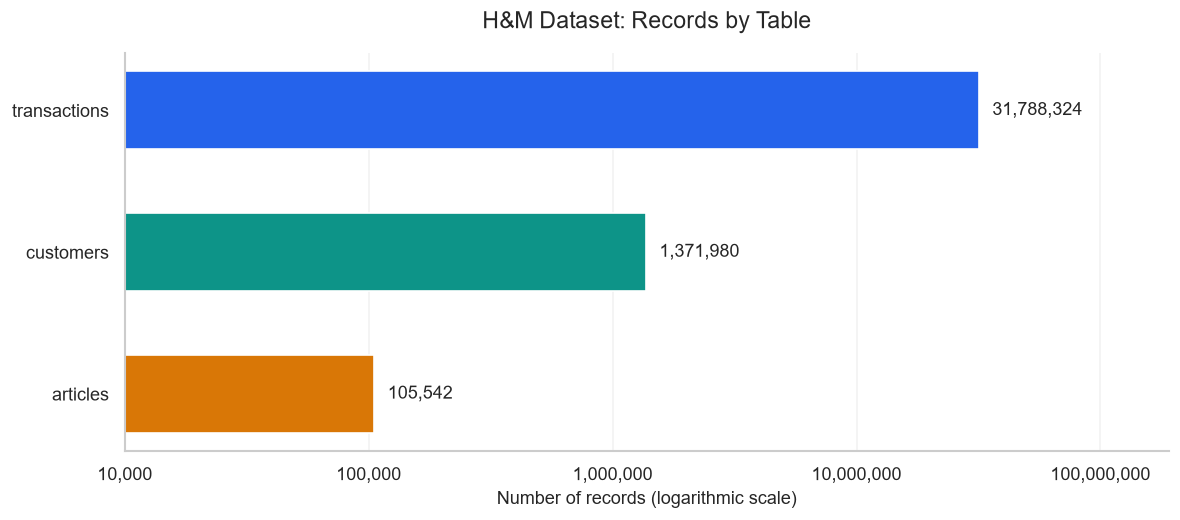

Graph saved to: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\figures\01_dataset_record_counts.png


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Use the numeric overview table created in the previous cell.
plot_data = dataset_overview.copy()

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.barh(
    plot_data["Table"],
    plot_data["Rows"],
    color=["#2563EB", "#0D9488", "#D97706"],
    height=0.55,
)

ax.set_xscale("log")
ax.set_xlim(10_000, plot_data["Rows"].max() * 6)
ax.invert_yaxis()

# Add exact counts next to the bars.
for position, count in enumerate(plot_data["Rows"]):
    ax.annotate(
        f"{count:,}",
        xy=(count, position),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
    )

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

ax.set_title("H&M Dataset: Records by Table", pad=15)
ax.set_xlabel("Number of records (logarithmic scale)")
ax.set_ylabel("")
ax.grid(axis="x", which="major", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# Save a high-resolution copy for the project report.
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "01_dataset_record_counts.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Graph saved to:", figure_path)

## 3. Columns and Data Types

**Question:** What information does each table contain, and how is it stored?

We inspect the schema of each prepared table before analyzing its values.

- VARCHAR stores text, including identifiers and category labels.
- DATE stores calendar dates.
- DOUBLE stores decimal numbers.
- SMALLINT and UTINYINT store integers.
- BOOLEAN stores True/False indicators.

A numeric-looking identifier is not a measurement. For example,
article IDs are stored as text to preserve leading zeros.

The displayed types describe our prepared Parquet files.

In [7]:
# Inspect column names and types without loading the full tables.
table_schemas = {}

for table_name in ["transactions", "customers", "articles"]:
    schema = con.execute(
        f"DESCRIBE {table_name}"
    ).fetchdf()

    schema = schema[["column_name", "column_type"]].rename(
        columns={
            "column_name": "Column",
            "column_type": "Data type",
        }
    )

    table_schemas[table_name] = schema

    print(f"\n{table_name.upper()} — {len(schema)} columns")
    display(schema)
    


TRANSACTIONS — 5 columns


,Column,Data type
0,t_dat,DATE
1,customer_id,VARCHAR
2,article_id,VARCHAR
3,price,DOUBLE
4,sales_channel_id,UTINYINT



CUSTOMERS — 10 columns


,Column,Data type
0,customer_id,VARCHAR
1,FN,UTINYINT
2,Active,UTINYINT
3,club_member_status,VARCHAR
4,fashion_news_frequency,VARCHAR
5,age,SMALLINT
6,postal_code,VARCHAR
7,age_missing,BOOLEAN
8,fn_missing,BOOLEAN
9,active_missing,BOOLEAN



ARTICLES — 26 columns


,Column,Data type
0,article_id,VARCHAR
1,product_code,VARCHAR
2,prod_name,VARCHAR
3,product_type_no,VARCHAR
4,product_type_name,VARCHAR
5,product_group_name,VARCHAR
6,graphical_appearance_no,VARCHAR
7,graphical_appearance_name,VARCHAR
8,colour_group_code,VARCHAR
9,colour_group_name,VARCHAR


## 4. Inspecting Sample Records

**Question:** What does a record in each table look like?

We inspect five records from each prepared table to understand
the values, category labels, and missing-value representations.

These records are a preview, not a representative statistical sample.
They cannot establish overall distributions or data quality.

Customer identifiers and postal codes are excluded from the displayed
preview. The underlying tables remain unchanged.

In [8]:
# Preview purchase records.
# Customer IDs are omitted from the displayed output.
print("TRANSACTIONS — 5 example purchase records")

transaction_preview = con.execute("""
    SELECT
        t_dat,
        article_id,
        price,
        sales_channel_id
    FROM transactions
    LIMIT 5
""").fetchdf()

display(transaction_preview)


# Preview customer attributes and missing-value indicators.
print("\nCUSTOMERS — 5 example profiles")

customer_preview = con.execute("""
    SELECT
        age,
        club_member_status,
        fashion_news_frequency,
        FN,
        Active,
        age_missing,
        fn_missing,
        active_missing
    FROM customers
    LIMIT 5
""").fetchdf()

display(customer_preview)


# Preview selected product attributes.
print("\nARTICLES — 5 example products")

article_preview = con.execute("""
    SELECT
        article_id,
        prod_name,
        product_type_name,
        product_group_name,
        colour_group_name,
        department_name,
        section_name,
        garment_group_name
    FROM articles
    LIMIT 5
""").fetchdf()

display(article_preview)

TRANSACTIONS — 5 example purchase records


,t_dat,article_id,price,sales_channel_id
0,2018-09-21,0642960002,0.020322,2
1,2018-09-21,0553881020,0.015237,1
2,2018-09-21,0611899001,0.004559,1
3,2018-09-21,0623283002,0.022864,1
4,2018-09-21,0660320001,0.019814,1



CUSTOMERS — 5 example profiles


,age,club_member_status,fashion_news_frequency,FN,Active,age_missing,fn_missing,active_missing
0,49,ACTIVE,NONE,<NA>,<NA>,False,True,True
1,25,ACTIVE,NONE,<NA>,<NA>,False,True,True
2,24,ACTIVE,NONE,<NA>,<NA>,False,True,True
3,54,ACTIVE,NONE,<NA>,<NA>,False,True,True
4,52,ACTIVE,REGULARLY,1,1,False,False,False



ARTICLES — 5 example products


,article_id,prod_name,product_type_name,product_group_name,colour_group_name,department_name,section_name,garment_group_name
0,0609847002,Christina suede cross,Bag,Accessories,Black,Small Bags,Womens Big accessories,Accessories
1,0609907001,Sun denim skirt,Skirt,Garment Lower body,Dark Blue,Trousers & Skirt,Womens Trend,Trousers
2,0609907002,Sun denim skirt,Skirt,Garment Lower body,Yellow,Trousers & Skirt,Womens Trend,Trousers
3,0609931001,Elefant blazer,Blazer,Garment Upper body,Black,Outwear & Blazers,Womens Trend,Dressed
4,0609938001,Vaja Cross Bag,Bag,Accessories,Dark Orange,Small Bags,Womens Big accessories,Accessories


## 5. Observation Period and Customer Coverage

**Questions**
1. What dates does the transaction data cover?
2. On how many dates are purchases recorded?
3. How many customer profiles have purchases in this period?

We distinguish all customer profiles from customers with observed
purchases. A profile with no purchases in this dataset is not
automatically a churned customer.

Date coverage describes the available records. It does not prove
that every real-world transaction was included.

In [9]:
# Measure the transaction observation period.
date_coverage = con.execute("""
    SELECT
        MIN(t_dat) AS first_purchase_date,
        MAX(t_dat) AS last_purchase_date,
        DATE_DIFF('day', MIN(t_dat), MAX(t_dat)) + 1
            AS calendar_days_in_period,
        COUNT(DISTINCT t_dat) AS dates_with_purchases
    FROM transactions
""").fetchdf()

date_coverage["dates_without_records"] = (
    date_coverage["calendar_days_in_period"]
    - date_coverage["dates_with_purchases"]
)

print("TRANSACTION DATE COVERAGE")
display(date_coverage)


# Match customer profiles to distinct purchasing customer IDs.
customer_coverage = con.execute("""
    WITH purchasing_customers AS (
        SELECT DISTINCT customer_id
        FROM transactions
    )
    SELECT
        COUNT(*) AS total_customer_profiles,
        COUNT(p.customer_id) AS profiles_with_purchases,
        COUNT(*) - COUNT(p.customer_id) AS profiles_without_purchases
    FROM customers AS c
    LEFT JOIN purchasing_customers AS p
        ON c.customer_id = p.customer_id
""").fetchdf()

customer_coverage["profiles_with_purchases_pct"] = (
    100
    * customer_coverage["profiles_with_purchases"]
    / customer_coverage["total_customer_profiles"]
)

print("\nCUSTOMER COVERAGE")
display(customer_coverage.round(2))

TRANSACTION DATE COVERAGE


,first_purchase_date,last_purchase_date,calendar_days_in_period,dates_with_purchases,dates_without_records
0,2018-09-20,2020-09-22,734,734,0



CUSTOMER COVERAGE


,total_customer_profiles,profiles_with_purchases,profiles_without_purchases,profiles_with_purchases_pct
0,1371980,1362281,9699,99.29


### 5.1 Customer Purchase Coverage

**Question:** What proportion of customer profiles has at least one
purchase in the observation period?

We display the percentage of profiles with and without observed
purchases. The denominator is all customer profiles, and each profile
is counted once.

This measures dataset purchase coverage, not customer retention.

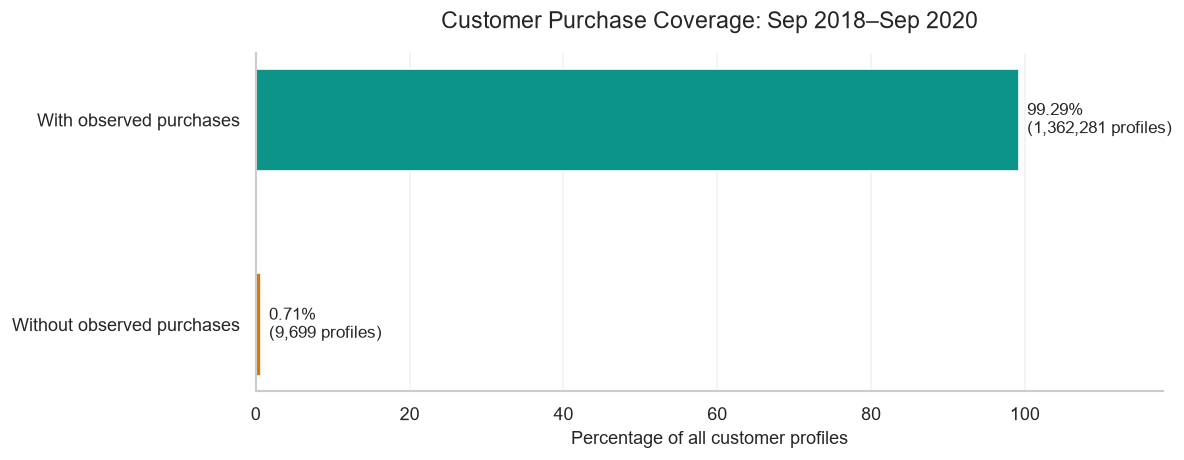

Graph saved to: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\figures\02_customer_purchase_coverage.png


In [10]:
import matplotlib.pyplot as plt

coverage = customer_coverage.iloc[0]

counts = [
    int(coverage["profiles_with_purchases"]),
    int(coverage["profiles_without_purchases"]),
]

labels = ["With observed purchases", "Without observed purchases"]
total = int(coverage["total_customer_profiles"])
percentages = [100 * count / total for count in counts]

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(
    labels,
    percentages,
    color=["#0D9488", "#D97706"],
    height=0.5,
)

ax.invert_yaxis()
ax.set_xlim(0, 118)  # Leave space for labels beyond the 100% tick.
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("Percentage of all customer profiles")
ax.set_title("Customer Purchase Coverage: Sep 2018–Sep 2020", pad=15)

for bar, count, percentage in zip(bars, counts, percentages):
    ax.text(
        percentage + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.2f}%\n({count:,} profiles)",
        va="center",
        fontsize=10,
    )

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "02_customer_purchase_coverage.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Graph saved to:", figure_path)

### Findings and Implications

1. The transaction observation period spans 734 days, from
   20 September 2018 to 22 September 2020.

2. Every date in this interval contains purchase records. There are
   no entirely absent transaction dates, although this does not prove
   that every real-world purchase was captured.

3. Of 1,371,980 customer profiles, 1,362,281 (99.29%) have at least
   one observed purchase. The remaining 9,699 (0.71%) have none.

4. Profiles without observed purchases will be distinguished from
   purchasing customers in behavioral analysis. They cannot receive
   purchase-based recency or frequency measures in the same way.

5. Purchase coverage is not a retention rate. Having one purchase
   anywhere in the observation period does not imply continued activity.

6. September 2018 and September 2020 are partially observed months.
   Raw monthly totals for these boundary months should not be compared
   directly with full-month totals.

7. Future inactivity labels must use a complete follow-up period.
   Purchases after 22 September 2020 are not observed in this dataset.

## 6. Data Quality: Missing Values

**Question:** Which columns contain missing values, and how common
are they?

For each column, we calculate:
- Number of SQL NULL values.
- Number of blank or whitespace-only strings for text columns.
- Total missing values and their percentage of table rows.

NULL and blank-string counts are mutually exclusive in this analysis.
Literal category labels such as "NONE" are not automatically treated
as missing.

This check uses the prepared Parquet files. No values are changed.
Missing-value indicators are included to check their completeness,
but their True/False values are not themselves missing values.

In [11]:
missing_rows = []

for table_name in ["transactions", "customers", "articles"]:
    schema = con.execute(f"DESCRIBE {table_name}").fetchall()

    # Build all column checks into one aggregate query per table.
    expressions = ["COUNT(*) AS total_rows"]

    for index, column in enumerate(schema):
        column_name, column_type = column[0], column[1]
        quoted_name = '"' + column_name.replace('"', '""') + '"'

        expressions.append(
            f"COUNT(*) - COUNT({quoted_name}) AS null_{index}"
        )

        if column_type == "VARCHAR":
            expressions.append(
                f"COUNT(*) FILTER (WHERE TRIM({quoted_name}) = '') "
                f"AS blank_{index}"
            )
        else:
            expressions.append(f"0 AS blank_{index}")

    result = con.execute(
        f"SELECT {', '.join(expressions)} FROM {table_name}"
    ).fetchone()

    total_rows = int(result[0])

    for index, column in enumerate(schema):
        null_count = int(result[1 + 2 * index])
        blank_count = int(result[2 + 2 * index])
        missing_count = null_count + blank_count

        missing_rows.append({
            "Table": table_name,
            "Column": column[0],
            "Data type": column[1],
            "Total rows": total_rows,
            "NULL count": null_count,
            "Blank count": blank_count,
            "Missing count": missing_count,
            "Missing (%)": (
                100 * missing_count / total_rows
                if total_rows else float("nan")
            ),
        })

missing_summary = pd.DataFrame(missing_rows)

missing_summary = missing_summary.sort_values(
    ["Missing (%)", "Table", "Column"],
    ascending=[False, True, True],
).reset_index(drop=True)

# Display columns with missing values.
missing_columns = missing_summary.loc[
    missing_summary["Missing count"] > 0
].copy()

print(f"Columns checked: {len(missing_summary)}")
print(f"Columns with missing values: {len(missing_columns)}")

display(
    missing_columns[
        ["Table", "Column", "NULL count", "Blank count",
         "Missing count", "Missing (%)"]
    ].round({"Missing (%)": 2})
)

# Save the complete audit, including columns with zero missing values.
tables_dir = project_root / "reports" / "eda_tables"
tables_dir.mkdir(parents=True, exist_ok=True)

missing_summary.to_csv(
    tables_dir / "missing_value_summary.csv",
    index=False,
)

Columns checked: 41
Columns with missing values: 6


,Table,Column,NULL count,Blank count,Missing count,Missing (%)
0,customers,Active,907576,0,907576,66.15
1,customers,FN,895050,0,895050,65.24
2,customers,fashion_news_frequency,16009,0,16009,1.17
3,customers,age,15861,0,15861,1.16
4,customers,club_member_status,6062,0,6062,0.44
5,articles,detail_desc,416,0,416,0.39


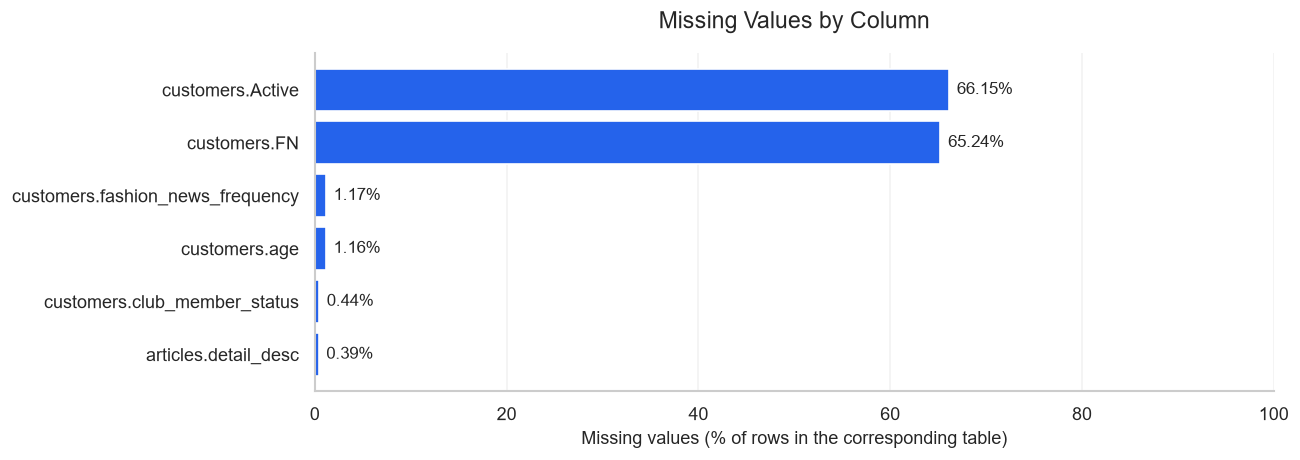

In [12]:
import matplotlib.pyplot as plt

if missing_columns.empty:
    print("No NULL or blank values were found.")
else:
    chart_data = missing_columns.sort_values(
        "Missing (%)", ascending=True
    )

    labels = chart_data["Table"] + "." + chart_data["Column"]

    fig, ax = plt.subplots(
        figsize=(11, max(4, len(chart_data) * 0.55))
    )

    bars = ax.barh(
        labels,
        chart_data["Missing (%)"],
        color="#2563EB",
    )

    for bar, percentage in zip(bars, chart_data["Missing (%)"]):
        ax.text(
            percentage + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f"{percentage:.2f}%",
            va="center",
            fontsize=10,
        )

    ax.set_xlim(0, 100)
    ax.set_xlabel("Missing values (% of rows in the corresponding table)")
    ax.set_title("Missing Values by Column", pad=15)
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    figures_dir = project_root / "reports" / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        figures_dir / "03_missing_values.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

In [13]:
# Compare all four combinations of missingness.
flag_missingness = con.execute("""
    SELECT
        CASE WHEN Active IS NULL
             THEN 'Missing' ELSE 'Present' END AS active_status,
        CASE WHEN FN IS NULL
             THEN 'Missing' ELSE 'Present' END AS fn_status,
        COUNT(*) AS customer_count,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS customer_pct
    FROM customers
    GROUP BY 1, 2
    ORDER BY 1, 2
""").fetchdf()

display(flag_missingness)

,active_status,fn_status,customer_count,customer_pct
0,Missing,Missing,895050,65.24
1,Missing,Present,12526,0.91
2,Present,Present,464404,33.85


### 6.1 Overlap Between Missing Active and FN Values

**Question:** Do Active and FN tend to be missing in the same profiles?

We compare their missingness in a 2 × 2 table. Each cell shows the
customer count and percentage of all customer profiles.

An unobserved combination is displayed as zero. "Present" means
non-NULL; it does not independently describe the customer's behavior.

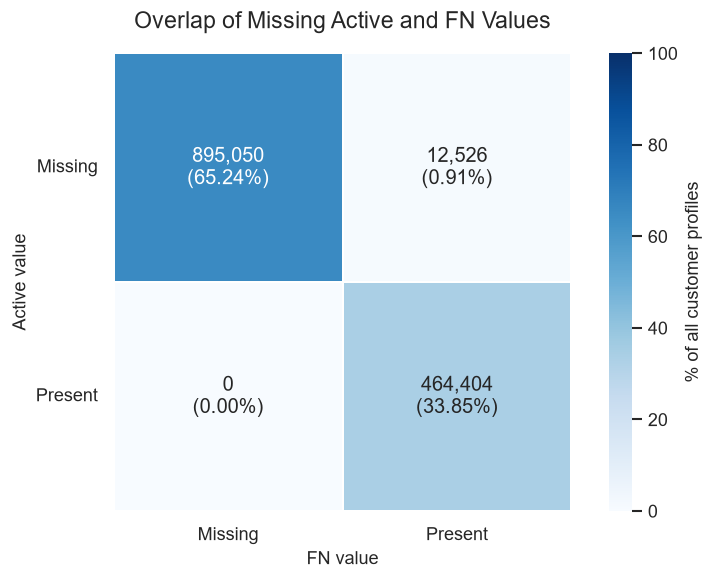

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

status_order = ["Missing", "Present"]

# Include all four combinations, even those absent from the SQL output.
count_matrix = (
    flag_missingness.pivot(
        index="active_status",
        columns="fn_status",
        values="customer_count",
    )
    .reindex(index=status_order, columns=status_order)
    .fillna(0)
    .astype("int64")
)

total_profiles = int(count_matrix.to_numpy().sum())
percentage_matrix = count_matrix / total_profiles * 100

# Labels show both counts and percentages.
annotations = count_matrix.astype(str)

for row in status_order:
    for column in status_order:
        count = count_matrix.loc[row, column]
        percentage = percentage_matrix.loc[row, column]

        annotations.loc[row, column] = (
            f"{count:,}\n({percentage:.2f}%)"
        )

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    percentage_matrix,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=1,
    square=True,
    cbar_kws={"label": "% of all customer profiles"},
    ax=ax,
)

ax.set_title("Overlap of Missing Active and FN Values", pad=15)
ax.set_xlabel("FN value")
ax.set_ylabel("Active value")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "04_flag_missingness_overlap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [15]:
key_checks = []

for table_name, key_column in [
    ("customers", "customer_id"),
    ("articles", "article_id"),
]:
    result = con.execute(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(*) FILTER (
                WHERE {key_column} IS NULL
                   OR TRIM({key_column}) = ''
            ) AS missing_id_rows,
            COUNT({key_column}) FILTER (
                WHERE TRIM({key_column}) <> ''
            ) AS valid_id_rows,
            COUNT(DISTINCT {key_column}) FILTER (
                WHERE TRIM({key_column}) <> ''
            ) AS unique_valid_ids
        FROM {table_name}
    """).fetchone()

    total_rows, missing_ids, valid_ids, unique_ids = result
    repeated_rows = valid_ids - unique_ids

    key_checks.append({
        "Table": table_name,
        "Key": key_column,
        "Total rows": total_rows,
        "Missing IDs": missing_ids,
        "Unique valid IDs": unique_ids,
        "Extra rows with repeated IDs": repeated_rows,
        "Status": (
            "PASS"
            if missing_ids == 0 and repeated_rows == 0
            else "REVIEW"
        ),
    })

key_check_summary = pd.DataFrame(key_checks)
display(key_check_summary)

,Table,Key,Total rows,Missing IDs,Unique valid IDs,Extra rows with repeated IDs,Status
0,customers,customer_id,1371980,0,1371980,0,PASS
1,articles,article_id,105542,0,105542,0,PASS


In [16]:
from collections import Counter

# Count how often each complete transaction pattern occurs.
# Identical rows must have the same date, so monthly processing
# preserves the exact result.
months = con.execute("""
    SELECT DISTINCT DATE_TRUNC('month', t_dat)::DATE AS month
    FROM transactions
    ORDER BY month
""").fetchall()

occurrence_counts = Counter()

for (month_start,) in months:
    month_result = con.execute("""
        WITH transaction_patterns AS (
            SELECT
                t_dat,
                customer_id,
                article_id,
                price,
                sales_channel_id,
                COUNT(*) AS occurrences
            FROM transactions
            WHERE t_dat >= ?
              AND t_dat < CAST(? AS DATE) + INTERVAL '1 month'
            GROUP BY
                t_dat, customer_id, article_id,
                price, sales_channel_id
        )
        SELECT
            occurrences,
            COUNT(*) AS pattern_count
        FROM transaction_patterns
        GROUP BY occurrences
    """, [month_start, month_start]).fetchall()

    for occurrences, pattern_count in month_result:
        occurrence_counts[int(occurrences)] += int(pattern_count)

    print(f"Checked {month_start:%Y-%m}")

transaction_repetition = pd.DataFrame(
    sorted(occurrence_counts.items()),
    columns=["Occurrences per pattern", "Number of patterns"],
)

total_records = sum(
    occurrences * patterns
    for occurrences, patterns in occurrence_counts.items()
)

unique_patterns = sum(occurrence_counts.values())

repeated_patterns = sum(
    patterns
    for occurrences, patterns in occurrence_counts.items()
    if occurrences > 1
)

records_in_repeated_patterns = sum(
    occurrences * patterns
    for occurrences, patterns in occurrence_counts.items()
    if occurrences > 1
)

extra_matching_records = total_records - unique_patterns

repetition_summary = pd.DataFrame({
    "Metric": [
        "Total purchase records",
        "Distinct five-column patterns",
        "Patterns occurring more than once",
        "All records in repeated patterns",
        "Matching records beyond first occurrence",
        "Beyond-first records (% of all records)",
    ],
    "Value": [
        f"{total_records:,}",
        f"{unique_patterns:,}",
        f"{repeated_patterns:,}",
        f"{records_in_repeated_patterns:,}",
        f"{extra_matching_records:,}",
        f"{100 * extra_matching_records / total_records:.2f}%"
        if total_records else "N/A",
    ],
})

display(repetition_summary)

Checked 2018-09
Checked 2018-10
Checked 2018-11
Checked 2018-12
Checked 2019-01
Checked 2019-02
Checked 2019-03
Checked 2019-04
Checked 2019-05
Checked 2019-06
Checked 2019-07
Checked 2019-08
Checked 2019-09
Checked 2019-10
Checked 2019-11
Checked 2019-12
Checked 2020-01
Checked 2020-02
Checked 2020-03
Checked 2020-04
Checked 2020-05
Checked 2020-06
Checked 2020-07
Checked 2020-08
Checked 2020-09


,Metric,Value
0,Total purchase records,"31,788,324"
1,Distinct five-column patterns,"28,813,419"
2,Patterns occurring more than once,"2,543,908"
3,All records in repeated patterns,"5,518,813"
4,Matching records beyond first occurrence,"2,974,905"
5,Beyond-first records (% of all records),9.36%


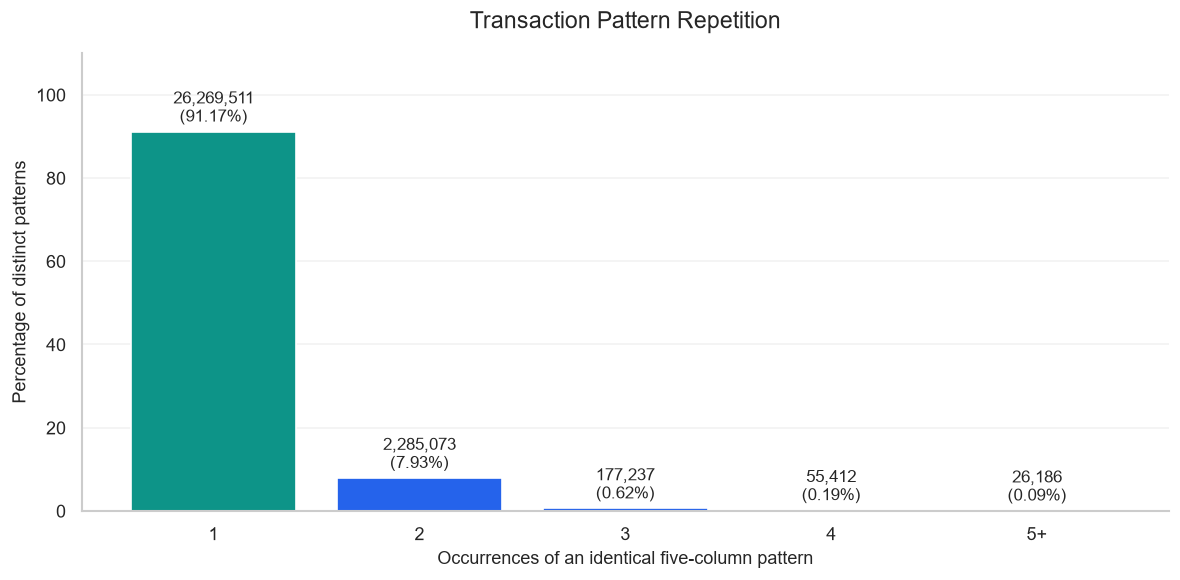

In [17]:
import matplotlib.pyplot as plt

# Group high repetition counts to keep the chart readable.
repetition_plot = transaction_repetition.copy()

repetition_plot["Occurrence group"] = (
    repetition_plot["Occurrences per pattern"]
    .map(lambda value: str(value) if value < 5 else "5+")
)

group_order = ["1", "2", "3", "4", "5+"]

pattern_counts = (
    repetition_plot.groupby("Occurrence group")["Number of patterns"]
    .sum()
    .reindex(group_order, fill_value=0)
)

pattern_percentages = 100 * pattern_counts / pattern_counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    group_order,
    pattern_percentages,
    color=["#0D9488", "#2563EB", "#2563EB", "#2563EB", "#2563EB"],
)

for bar, count, percentage in zip(
    bars, pattern_counts, pattern_percentages
):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20))
ax.set_xlabel("Occurrences of an identical five-column pattern")
ax.set_ylabel("Percentage of distinct patterns")
ax.set_title("Transaction Pattern Repetition", pad=15)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "05_transaction_pattern_repetition.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [18]:
relationship_checks = []

total_transactions = con.execute(
    "SELECT COUNT(*) FROM transactions"
).fetchone()[0]

for lookup_table, key_column in [
    ("customers", "customer_id"),
    ("articles", "article_id"),
]:
    # NOT EXISTS counts unmatched purchases without multiplying rows.
    unmatched_records = con.execute(f"""
        SELECT COUNT(*)
        FROM transactions AS t
        WHERE NOT EXISTS (
            SELECT 1
            FROM {lookup_table} AS lookup
            WHERE t.{key_column} = lookup.{key_column}
        )
    """).fetchone()[0]

    matched_records = total_transactions - unmatched_records

    relationship_checks.append({
        "Relationship": f"transactions → {lookup_table}",
        "Purchase records": total_transactions,
        "Matched records": matched_records,
        "Unmatched records": unmatched_records,
        "Match (%)": (
            100 * matched_records / total_transactions
            if total_transactions else float("nan")
        ),
        "Status": "PASS" if unmatched_records == 0 else "REVIEW",
    })

relationship_summary = pd.DataFrame(relationship_checks)

display(relationship_summary.round({"Match (%)": 2}))

,Relationship,Purchase records,Matched records,Unmatched records,Match (%),Status
0,transactions → customers,31788324,31788324,0,100.0,PASS
1,transactions → articles,31788324,31788324,0,100.0,PASS


In [19]:
# Check prices and channel codes in one transaction scan.
transaction_validity = con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE price IS NULL
        ) AS missing_prices,

        COUNT(*) FILTER (
            WHERE price IS NOT NULL AND NOT ISFINITE(price)
        ) AS nonfinite_prices,

        COUNT(*) FILTER (
            WHERE ISFINITE(price) AND price < 0
        ) AS negative_prices,

        COUNT(*) FILTER (
            WHERE price = 0
        ) AS zero_prices,

        MIN(price) FILTER (
            WHERE ISFINITE(price)
        ) AS minimum_finite_price,

        MAX(price) FILTER (
            WHERE ISFINITE(price)
        ) AS maximum_finite_price,

        COUNT(*) FILTER (
            WHERE sales_channel_id IS NULL
        ) AS missing_channels,

        COUNT(*) FILTER (
            WHERE sales_channel_id NOT IN (1, 2)
        ) AS unexpected_channels
    FROM transactions
""").fetchdf()

print("PRICE AND CHANNEL CHECKS")
display(transaction_validity.T.rename(columns={0: "Value"}))


# Use 0–120 as a broad age plausibility screen, not an H&M rule.
age_validity = con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE age IS NULL
        ) AS missing_ages,

        MIN(age) AS minimum_age,
        MAX(age) AS maximum_age,

        COUNT(*) FILTER (
            WHERE age < 0 OR age > 120
        ) AS ages_outside_plausibility_range
    FROM customers
""").fetchdf()

print("\nAGE CHECKS")
display(age_validity.T.rename(columns={0: "Value"}))


# Inspect the actual channel codes and their frequencies.
channel_counts = con.execute("""
    SELECT
        sales_channel_id,
        COUNT(*) AS purchase_records,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS purchase_record_pct
    FROM transactions
    GROUP BY sales_channel_id
    ORDER BY sales_channel_id
""").fetchdf()

print("\nSALES CHANNEL VALUES")
display(channel_counts)

PRICE AND CHANNEL CHECKS


,Value
missing_prices,0.000000
nonfinite_prices,0.000000
negative_prices,0.000000
zero_prices,0.000000
minimum_finite_price,0.000017
maximum_finite_price,0.591525
missing_channels,0.000000
unexpected_channels,0.000000



AGE CHECKS


,Value
missing_ages,15861
minimum_age,16
maximum_age,99
ages_outside_plausibility_range,0



SALES CHANNEL VALUES


,sales_channel_id,purchase_records,purchase_record_pct
0,1,9408462,29.6
1,2,22379862,70.4


## 7. Customer Age Distribution

We examine known ages across all customer profiles.
Missing ages are excluded from age statistics and explicitly reported.

This describes customer profiles, not purchase-weighted demographics.

In [20]:
# Summary statistics for all non-missing customer ages.
age_summary = con.execute("""
    SELECT
        COUNT(*) AS total_profiles,
        COUNT(age) AS profiles_with_age,
        COUNT(*) - COUNT(age) AS profiles_without_age,
        MIN(age) AS minimum,
        AVG(age) AS mean,
        STDDEV_SAMP(age) AS standard_deviation,
        QUANTILE_CONT(age, 0.25) AS q1,
        MEDIAN(age) AS median,
        QUANTILE_CONT(age, 0.75) AS q3,
        QUANTILE_CONT(age, 0.95) AS p95,
        MAX(age) AS maximum
    FROM customers
""").fetchdf()

display(age_summary.T.rename(columns={0: "Value"}).round(2))

# Retrieve only the count at each age, not all customer records.
age_distribution = con.execute("""
    SELECT
        age,
        COUNT(*) AS customer_count
    FROM customers
    WHERE age IS NOT NULL
    GROUP BY age
    ORDER BY age
""").fetchdf()

,Value
total_profiles,1371980.00
profiles_with_age,1356119.00
profiles_without_age,15861.00
minimum,16.00
mean,36.39
standard_deviation,14.31
q1,24.00
median,32.00
q3,49.00
p95,62.00


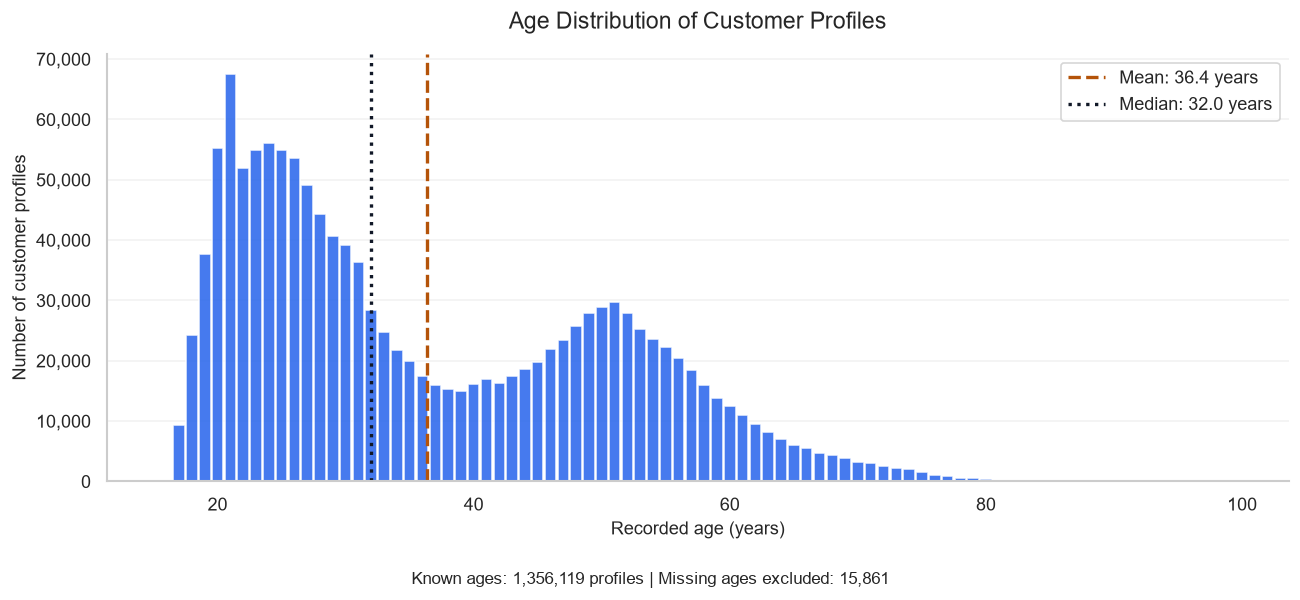

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

stats = age_summary.iloc[0]

fig, ax = plt.subplots(figsize=(11, 5))

# One bar per integer age, with gaps retained for unobserved ages.
ax.bar(
    age_distribution["age"],
    age_distribution["customer_count"],
    width=0.9,
    color="#2563EB",
    alpha=0.85,
)

ax.axvline(
    stats["mean"],
    color="#B45309",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {stats['mean']:.1f} years",
)

ax.axvline(
    stats["median"],
    color="#111827",
    linestyle=":",
    linewidth=2,
    label=f"Median: {stats['median']:.1f} years",
)

ax.set_title("Age Distribution of Customer Profiles", pad=15)
ax.set_xlabel("Recorded age (years)")
ax.set_ylabel("Number of customer profiles")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.5, 0.01,
    f"Known ages: {int(stats['profiles_with_age']):,} profiles | "
    f"Missing ages excluded: {int(stats['profiles_without_age']):,}",
    ha="center",
    fontsize=10,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "06_customer_age_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [22]:
# Calculate thresholds from the full known-age summary.
age_stats = age_summary.iloc[0]

q1 = float(age_stats["q1"])
median = float(age_stats["median"])
q3 = float(age_stats["q3"])

iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Use exact age frequencies to count flagged customer profiles.
below = age_distribution["age"] < lower_fence
above = age_distribution["age"] > upper_fence
flagged = below | above

known_count = int(age_distribution["customer_count"].sum())
flagged_count = int(
    age_distribution.loc[flagged, "customer_count"].sum()
)

age_outlier_summary = pd.DataFrame({
    "Metric": [
        "Q1",
        "Median",
        "Q3",
        "IQR",
        "Lower fence",
        "Upper fence",
        "Profiles below lower fence",
        "Profiles above upper fence",
        "Total flagged profiles",
        "Flagged (% of known ages)",
    ],
    "Value": [
        q1,
        median,
        q3,
        iqr,
        lower_fence,
        upper_fence,
        int(age_distribution.loc[below, "customer_count"].sum()),
        int(age_distribution.loc[above, "customer_count"].sum()),
        flagged_count,
        100 * flagged_count / known_count,
    ],
})

display(age_outlier_summary.round(2))

,Metric,Value
0,Q1,24.00
1,Median,32.00
2,Q3,49.00
3,IQR,25.00
4,Lower fence,-13.50
5,Upper fence,86.50
6,Profiles below lower fence,0.00
7,Profiles above upper fence,214.00
8,Total flagged profiles,214.00
9,Flagged (% of known ages),0.02


C:\Users\Admin\AppData\Local\Temp\ipykernel_2340\1300294909.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.bxp(


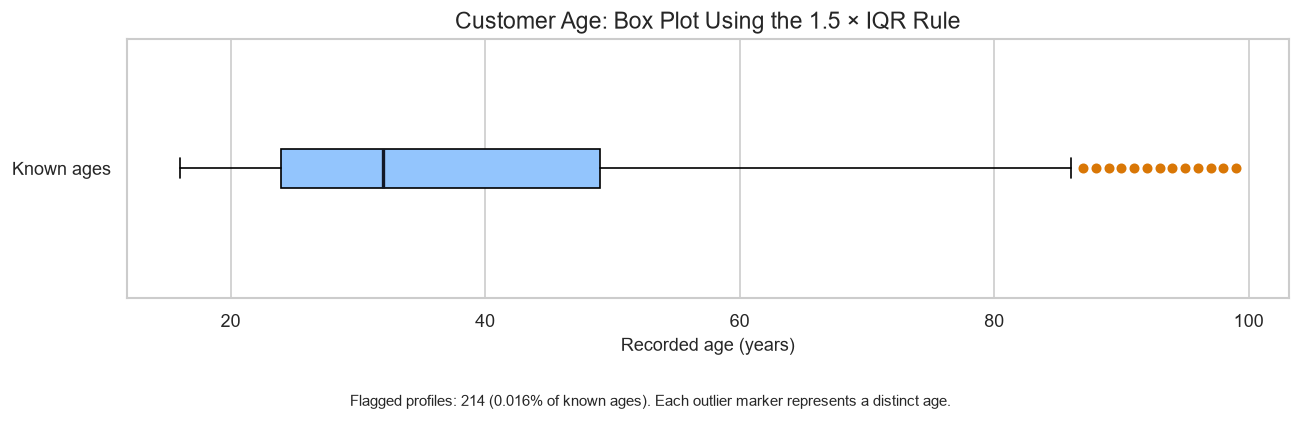

In [23]:
import matplotlib.pyplot as plt

# Whiskers end at observed ages within the IQR fences.
within_fences = age_distribution.loc[~flagged, "age"]

box_statistics = {
    "q1": q1,
    "med": median,
    "q3": q3,
    "whislo": float(within_fences.min()),
    "whishi": float(within_fences.max()),
    # One marker per distinct flagged age, not per customer.
    "fliers": age_distribution.loc[flagged, "age"].tolist(),
}

fig, ax = plt.subplots(figsize=(11, 3.5))

ax.bxp(
    [box_statistics],
    vert=False,
    patch_artist=True,
    boxprops={"facecolor": "#93C5FD"},
    medianprops={"color": "#111827", "linewidth": 2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#D97706",
        "markeredgecolor": "#D97706",
        "markersize": 5,
    },
)

ax.set_yticks([1])
ax.set_yticklabels(["Known ages"])
ax.set_xlabel("Recorded age (years)")
ax.set_title("Customer Age: Box Plot Using the 1.5 × IQR Rule")
ax.grid(axis="y", visible=False)

fig.text(
    0.5, 0.01,
    f"Flagged profiles: {flagged_count:,} "
    f"({100 * flagged_count / known_count:.3f}% of known ages). "
    "Each outlier marker represents a distinct age.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "07_customer_age_boxplot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

**Finding and decision:** The 1.5 × IQR rule flags 214 profiles
(approximately 0.016% of known ages). We retain these values because
statistical rarity alone does not establish a recording error.

## 8. Purchase Price Distribution

We analyze recorded prices across purchase records, retaining repeated
purchases. Results are therefore purchase-weighted, rather than giving
each distinct article equal weight.

Prices are expressed in dataset units.

In [24]:
# Calculate exact price statistics in DuckDB.
# Only the single summary row is returned to pandas.
price_summary = con.execute("""
    SELECT
        COUNT(*) AS purchase_records,
        MIN(price) AS minimum,
        AVG(price) AS mean,
        STDDEV_SAMP(price) AS standard_deviation,
        QUANTILE_CONT(
            price,
            [0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
        ) AS percentiles,
        MAX(price) AS maximum
    FROM transactions
    WHERE price IS NOT NULL
      AND ISFINITE(price)
      AND price > 0
""").fetchdf()

# Expand the percentile list into named columns.
percentile_names = ["p01", "q1", "median", "q3", "p95", "p99"]
percentile_values = price_summary.at[0, "percentiles"]

for name, value in zip(percentile_names, percentile_values):
    price_summary[name] = float(value)

price_summary = price_summary.drop(columns="percentiles")

display(
    price_summary[
        [
            "purchase_records",
            "minimum",
            "p01",
            "q1",
            "median",
            "mean",
            "q3",
            "p95",
            "p99",
            "maximum",
            "standard_deviation",
        ]
    ].T.rename(columns={0: "Value"}).round(6)
)

,Value
purchase_records,3.178832e+07
minimum,1.700000e-05
p01,3.576000e-03
q1,1.581400e-02
median,2.540700e-02
mean,2.782900e-02
q3,3.388100e-02
p95,5.930500e-02
p99,1.002200e-01
maximum,5.915250e-01


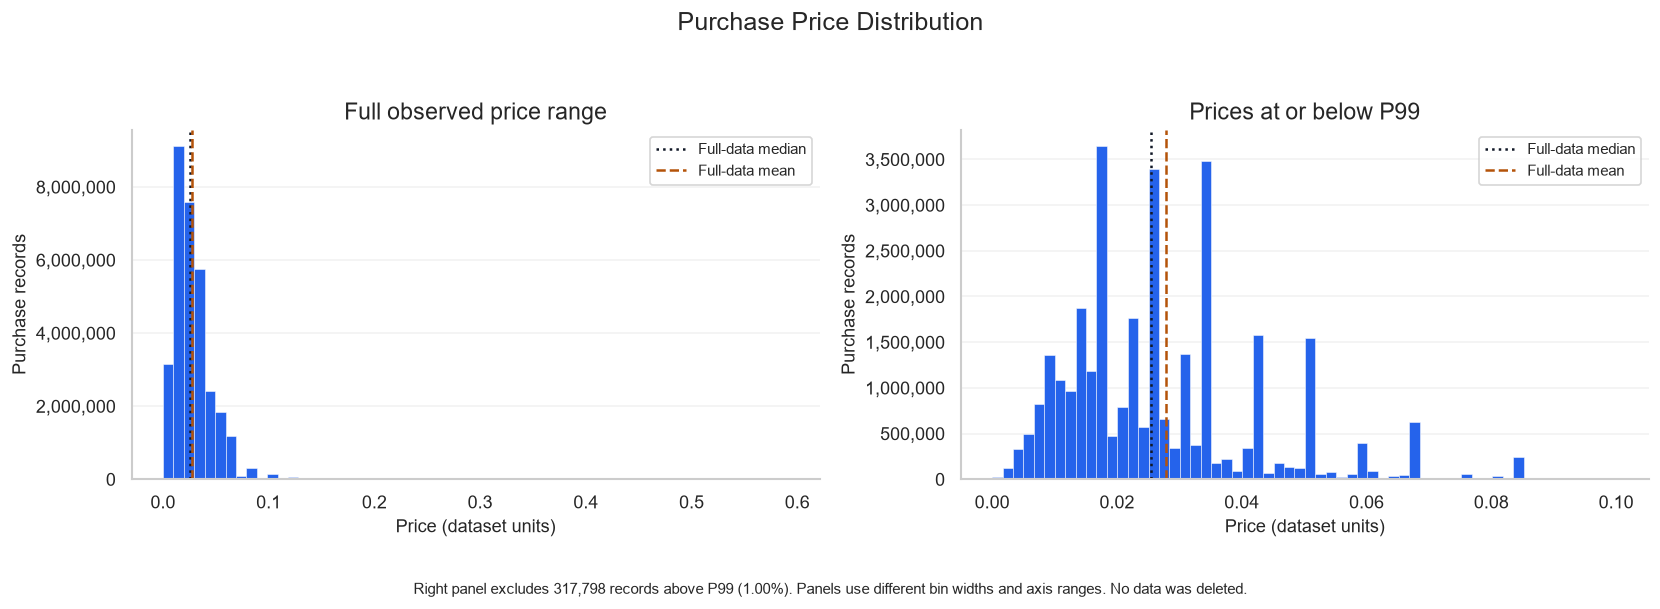

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

price_stats = price_summary.iloc[0]

full_upper = float(price_stats["maximum"])
central_upper = float(price_stats["p99"])
number_of_bins = 60

def get_price_bins(upper_limit):
    # Include the upper endpoint in the final bin.
    result = con.execute("""
        SELECT
            LEAST(
                CAST(FLOOR(price / ? * ?) AS INTEGER),
                ?
            ) AS bin_id,
            COUNT(*) AS purchase_records
        FROM transactions
        WHERE price > 0
          AND ISFINITE(price)
          AND price <= ?
        GROUP BY bin_id
        ORDER BY bin_id
    """, [
        upper_limit,
        number_of_bins,
        number_of_bins - 1,
        upper_limit,
    ]).fetchdf()

    counts = (
        result.set_index("bin_id")["purchase_records"]
        .reindex(range(number_of_bins), fill_value=0)
    )

    edges = np.linspace(0, upper_limit, number_of_bins + 1)
    return edges, counts.to_numpy()


full_edges, full_counts = get_price_bins(full_upper)
central_edges, central_counts = get_price_bins(central_upper)

total_records = int(price_stats["purchase_records"])
excluded_records = total_records - int(central_counts.sum())

assert int(full_counts.sum()) == total_records, \
    "Full histogram counts do not match the price summary."

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, edges, counts, title in [
    (axes[0], full_edges, full_counts, "Full observed price range"),
    (axes[1], central_edges, central_counts, "Prices at or below P99"),
]:
    ax.bar(
        edges[:-1],
        counts,
        width=np.diff(edges),
        align="edge",
        color="#2563EB",
        edgecolor="white",
        linewidth=0.3,
    )

    ax.axvline(
        float(price_stats["median"]),
        color="#111827",
        linestyle=":",
        label="Full-data median",
    )

    ax.axvline(
        float(price_stats["mean"]),
        color="#B45309",
        linestyle="--",
        label="Full-data mean",
    )

    ax.set_title(title)
    ax.set_xlabel("Price (dataset units)")
    ax.set_ylabel("Purchase records")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", alpha=0.25)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(fontsize=9)

fig.suptitle("Purchase Price Distribution", fontsize=15)

fig.text(
    0.5, 0.01,
    f"Right panel excludes {excluded_records:,} records above P99 "
    f"({100 * excluded_records / total_records:.2f}%). "
    "Panels use different bin widths and axis ranges. No data was deleted.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.07, 1, 0.94])

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "08_purchase_price_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

Purchase records: 31,788,324
Total sales value: 884,645.97 dataset units
Average purchase price: 0.02783 dataset units


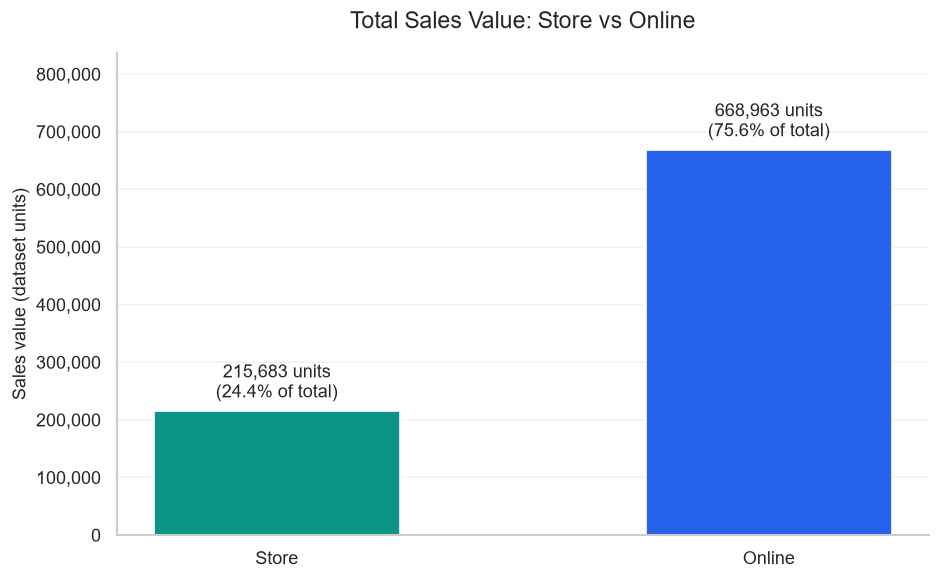

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Overall sales figures.
sales_overview = con.execute("""
    SELECT
        COUNT(*) AS purchase_records,
        SUM(price) AS total_sales_value,
        AVG(price) AS average_purchase_price
    FROM transactions
""").fetchdf()

summary = sales_overview.iloc[0]

print(f"Purchase records: {int(summary['purchase_records']):,}")
print(
    f"Total sales value: {summary['total_sales_value']:,.2f} "
    "dataset units"
)
print(
    f"Average purchase price: {summary['average_purchase_price']:.5f} "
    "dataset units"
)

# Compare the total sales value of the two channels.
channel_sales = con.execute("""
    SELECT
        sales_channel_id,
        SUM(price) AS total_sales_value
    FROM transactions
    GROUP BY sales_channel_id
    ORDER BY sales_channel_id
""").fetchdf()

channel_sales["Channel"] = channel_sales["sales_channel_id"].map({
    1: "Store",
    2: "Online",
})

channel_sales["Sales share (%)"] = (
    100
    * channel_sales["total_sales_value"]
    / channel_sales["total_sales_value"].sum()
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    channel_sales["Channel"],
    channel_sales["total_sales_value"],
    color=["#0D9488", "#2563EB"],
    width=0.5,
)

for bar, value, share in zip(
    bars,
    channel_sales["total_sales_value"],
    channel_sales["Sales share (%)"],
):
    ax.annotate(
        f"{value:,.0f} units\n({share:.1f}% of total)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=11,
    )

ax.set_title("Total Sales Value: Store vs Online", pad=15)
ax.set_ylabel("Sales value (dataset units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, channel_sales["total_sales_value"].max() * 1.25)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "09_total_sales_by_channel.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [27]:
channel_comparison = con.execute("""
    SELECT
        CASE sales_channel_id
            WHEN 1 THEN 'Store'
            WHEN 2 THEN 'Online'
        END AS channel,
        COUNT(*) AS purchase_records,
        SUM(price) AS sales_value,
        AVG(price) AS average_purchase_price
    FROM transactions
    GROUP BY sales_channel_id
    ORDER BY sales_channel_id
""").fetchdf()

channel_comparison["purchase_share_pct"] = (
    100
    * channel_comparison["purchase_records"]
    / channel_comparison["purchase_records"].sum()
)

channel_comparison["sales_share_pct"] = (
    100
    * channel_comparison["sales_value"]
    / channel_comparison["sales_value"].sum()
)

# Format a copy while keeping the original values numeric.
channel_display = channel_comparison.copy()

channel_display["purchase_records"] = (
    channel_display["purchase_records"].map("{:,.0f}".format)
)
channel_display["sales_value"] = (
    channel_display["sales_value"].map("{:,.2f}".format)
)
channel_display["average_purchase_price"] = (
    channel_display["average_purchase_price"].map("{:.5f}".format)
)

display(
    channel_display.round({
        "purchase_share_pct": 2,
        "sales_share_pct": 2,
    })
)

average_prices = channel_comparison.set_index(
    "channel"
)["average_purchase_price"]

difference_pct = (
    average_prices["Online"] / average_prices["Store"] - 1
) * 100

print(
    f"Online's average price per purchase record is "
    f"{difference_pct:.1f}% higher than Store's."
)

,channel,purchase_records,sales_value,average_purchase_price,purchase_share_pct,sales_share_pct
0,Store,"9,408,462","215,682.83",0.02292,29.6,24.38
1,Online,"22,379,862","668,963.15",0.02989,70.4,75.62


Online's average price per purchase record is 30.4% higher than Store's.


## 9. Monthly Sales Trends

We sum purchase prices by calendar month to examine changes in sales
value over time.

September 2018 and September 2020 are partially observed months.
They are highlighted and excluded from highest/lowest full-month rankings.
Sales values are expressed in dataset units.

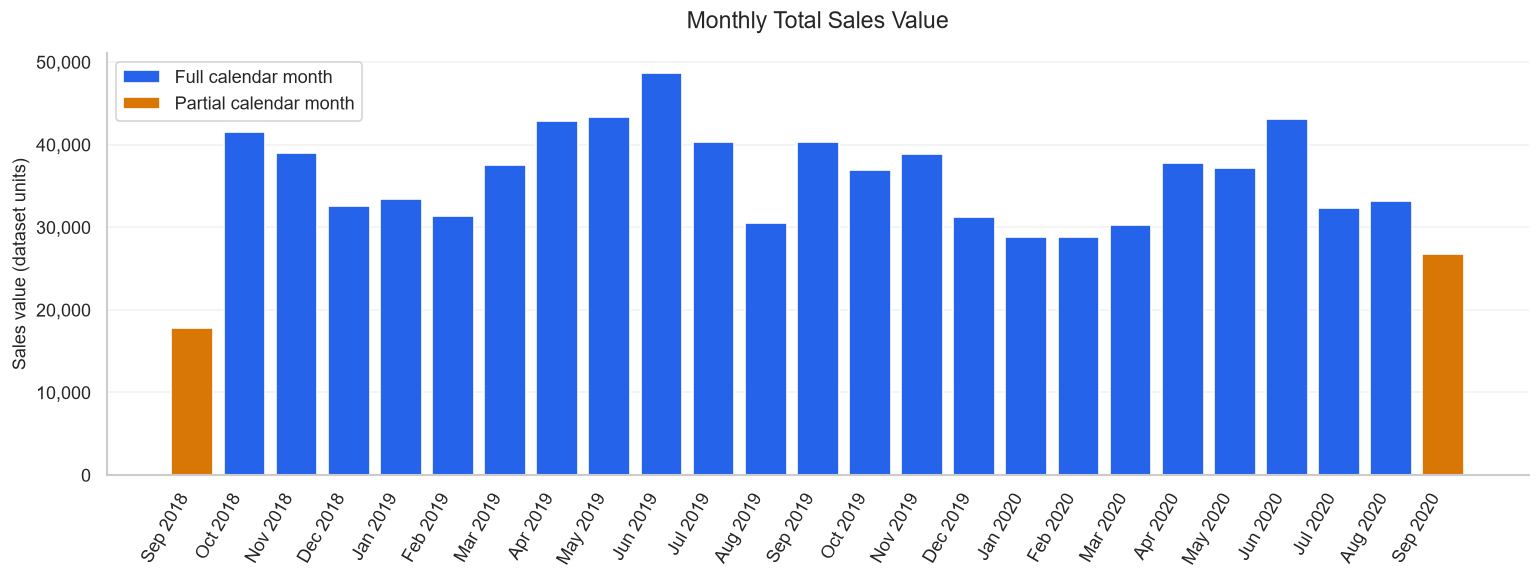

Highest full month: Jun 2019 — 48,648.42 dataset units
Lowest full month: Feb 2020 — 28,792.88 dataset units


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.patches import Patch

monthly_sales = con.execute("""
    SELECT
        DATE_TRUNC('month', t_dat)::DATE AS month,
        COUNT(*) AS purchase_records,
        SUM(price) AS sales_value,
        MIN(t_dat) AS first_recorded_date,
        MAX(t_dat) AS last_recorded_date,
        COUNT(DISTINCT t_dat) AS dates_with_purchases
    FROM transactions
    GROUP BY 1
    ORDER BY 1
""").fetchdf()

monthly_sales["month"] = pd.to_datetime(monthly_sales["month"])
monthly_sales["calendar_days"] = monthly_sales["month"].dt.days_in_month

# Earlier checks established that every date in the observed period
# has purchase records. Identify months covering all calendar dates.
monthly_sales["full_month"] = (
    monthly_sales["dates_with_purchases"]
    == monthly_sales["calendar_days"]
)

monthly_sales["month_label"] = (
    monthly_sales["month"].dt.strftime("%b %Y")
)

colors = [
    "#2563EB" if complete else "#D97706"
    for complete in monthly_sales["full_month"]
]

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    monthly_sales["month_label"],
    monthly_sales["sales_value"],
    color=colors,
)

ax.set_title("Monthly Total Sales Value", pad=15)
ax.set_xlabel("")
ax.set_ylabel("Sales value (dataset units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")

ax.legend(handles=[
    Patch(facecolor="#2563EB", label="Full calendar month"),
    Patch(facecolor="#D97706", label="Partial calendar month"),
])

ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "10_monthly_sales_value.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# Rank only full calendar months.
full_months = monthly_sales.loc[monthly_sales["full_month"]]

highest = full_months.loc[full_months["sales_value"].idxmax()]
lowest = full_months.loc[full_months["sales_value"].idxmin()]

print(
    f"Highest full month: {highest['month_label']} — "
    f"{highest['sales_value']:,.2f} dataset units"
)
print(
    f"Lowest full month: {lowest['month_label']} — "
    f"{lowest['sales_value']:,.2f} dataset units"
)

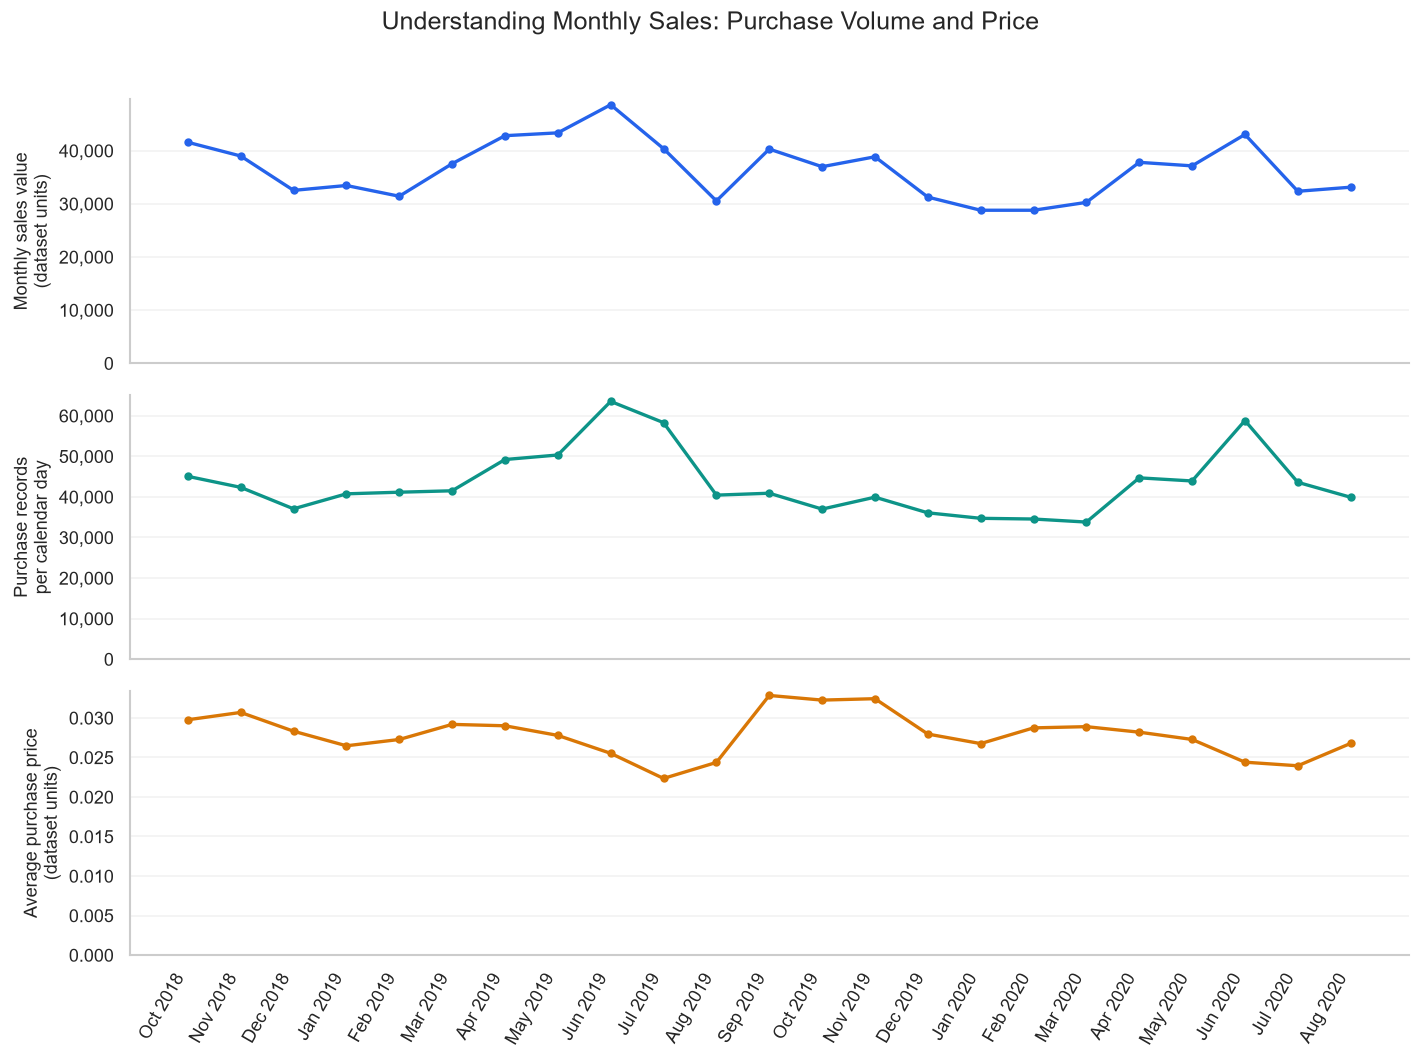

,month_label,calendar_days,purchase_records,purchases_per_day,average_purchase_price,sales_value
9,Jun 2019,30,1906202,63540.1,0.02552,48648.42
17,Feb 2020,29,1001859,34546.9,0.02874,28792.88


In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Use full months for this comparison.
monthly_drivers = (
    monthly_sales.loc[monthly_sales["full_month"]]
    .copy()
    .sort_values("month")
)

monthly_drivers["purchases_per_day"] = (
    monthly_drivers["purchase_records"]
    / monthly_drivers["calendar_days"]
)

monthly_drivers["average_purchase_price"] = (
    monthly_drivers["sales_value"]
    / monthly_drivers["purchase_records"]
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True,
)

chart_settings = [
    ("sales_value", "Monthly sales value\n(dataset units)", "#2563EB"),
    ("purchases_per_day", "Purchase records\nper calendar day", "#0D9488"),
    ("average_purchase_price", "Average purchase price\n(dataset units)", "#D97706"),
]

for ax, (column, label, color) in zip(axes, chart_settings):
    ax.plot(
        monthly_drivers["month_label"],
        monthly_drivers[column],
        marker="o",
        markersize=4,
        linewidth=2,
        color=color,
    )

    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[2].yaxis.set_major_formatter(StrMethodFormatter("{x:.3f}"))

plt.setp(axes[2].get_xticklabels(), rotation=60, ha="right")

fig.suptitle(
    "Understanding Monthly Sales: Purchase Volume and Price",
    fontsize=15,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "11_monthly_sales_drivers.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# Compare the highest and lowest sales months directly.
comparison = monthly_drivers.loc[
    monthly_drivers["month_label"].isin(["Jun 2019", "Feb 2020"]),
    [
        "month_label",
        "calendar_days",
        "purchase_records",
        "purchases_per_day",
        "average_purchase_price",
        "sales_value",
    ],
]

display(comparison.round({
    "purchases_per_day": 1,
    "average_purchase_price": 5,
    "sales_value": 2,
}))

June 2019 recorded approximately 69.0% more sales value than
February 2020. Daily purchase volume was 83.9% higher, while average
purchase price was 11.2% lower. Higher purchase volume therefore
accounted for the higher sales total, alongside one additional day.

These months belong to different seasons and years. The comparison
does not establish a causal explanation for the difference.

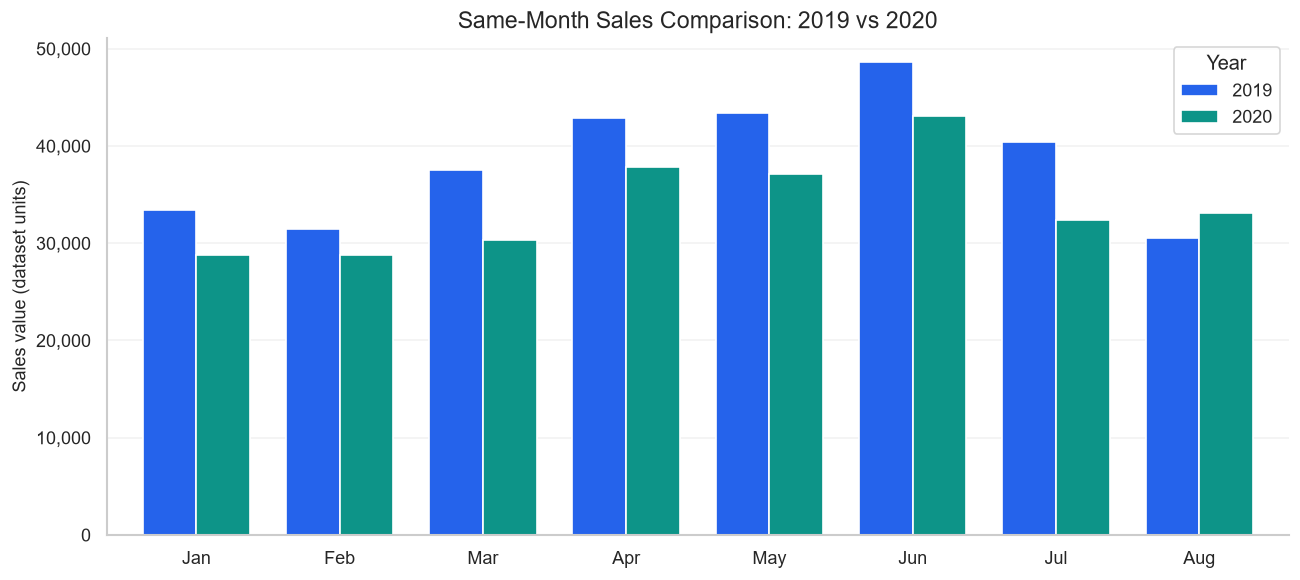

year,2019,2020,Change (%)
Month,,,
Jan,33449.98,28793.58,-13.92
Feb,31428.22,28792.88,-8.39
Mar,37549.02,30274.20,-19.37
Apr,42824.99,37808.49,-11.71
May,43357.50,37145.69,-14.33
Jun,48648.42,43055.36,-11.50
Jul,40387.13,32363.01,-19.87
Aug,30545.85,33130.50,8.46


In [30]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

year_comparison = monthly_sales.loc[
    monthly_sales["full_month"]
    & monthly_sales["month"].dt.year.isin([2019, 2020])
    & monthly_sales["month"].dt.month.between(1, 8)
].copy()

year_comparison["year"] = year_comparison["month"].dt.year
year_comparison["month_number"] = year_comparison["month"].dt.month

sales_by_year = year_comparison.pivot(
    index="month_number",
    columns="year",
    values="sales_value",
).sort_index()

sales_by_year["Change (%)"] = (
    (sales_by_year[2020] / sales_by_year[2019] - 1) * 100
)

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug"]
sales_by_year.index = month_names
sales_by_year.index.name = "Month"

fig, ax = plt.subplots(figsize=(11, 5))

sales_by_year[[2019, 2020]].plot.bar(
    ax=ax,
    color=["#2563EB", "#0D9488"],
    width=0.75,
    rot=0,
)

ax.set_title("Same-Month Sales Comparison: 2019 vs 2020")
ax.set_xlabel("")
ax.set_ylabel("Sales value (dataset units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Year")
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "12_same_month_sales_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(sales_by_year.round(2))

year,2019,2020,Change (units),Change (%)
channel,,,,
Store,77113.23,58348.45,-18764.78,-24.33
Online,231077.88,213015.26,-18062.62,-7.82


Jan–Aug 2019 sales: 308,191.11 dataset units
Jan–Aug 2020 sales: 271,363.71 dataset units
Combined sales change: -11.95%


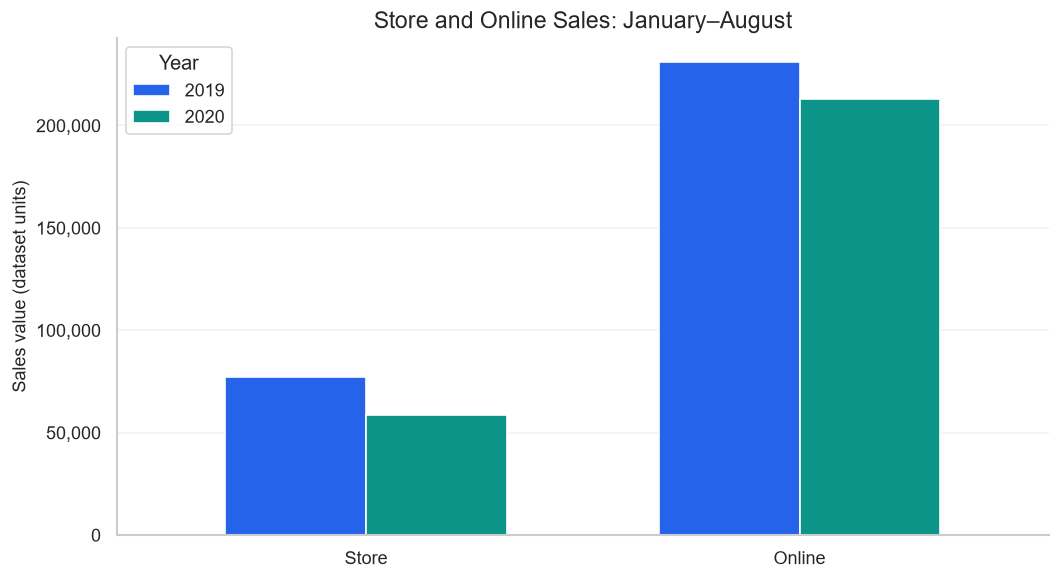

In [31]:
# Compare identical calendar-month coverage in both years.
channel_year_sales = con.execute("""
    SELECT
        YEAR(t_dat) AS year,
        CASE sales_channel_id
            WHEN 1 THEN 'Store'
            WHEN 2 THEN 'Online'
        END AS channel,
        COUNT(*) AS purchase_records,
        SUM(price) AS sales_value,
        AVG(price) AS average_purchase_price
    FROM transactions
    WHERE
        (t_dat >= DATE '2019-01-01'
         AND t_dat < DATE '2019-09-01')
        OR
        (t_dat >= DATE '2020-01-01'
         AND t_dat < DATE '2020-09-01')
    GROUP BY 1, 2
    ORDER BY 1, 2
""").fetchdf()

channel_year_comparison = channel_year_sales.pivot(
    index="channel",
    columns="year",
    values="sales_value",
).reindex(["Store", "Online"])

channel_year_comparison["Change (units)"] = (
    channel_year_comparison[2020]
    - channel_year_comparison[2019]
)

channel_year_comparison["Change (%)"] = (
    channel_year_comparison["Change (units)"]
    / channel_year_comparison[2019] * 100
)

display(channel_year_comparison.round(2))

# Calculate combined growth from totals, not averaged percentages.
total_2019 = channel_year_comparison[2019].sum()
total_2020 = channel_year_comparison[2020].sum()

print(f"Jan–Aug 2019 sales: {total_2019:,.2f} dataset units")
print(f"Jan–Aug 2020 sales: {total_2020:,.2f} dataset units")
print(
    f"Combined sales change: "
    f"{100 * (total_2020 / total_2019 - 1):.2f}%"
)

ax = channel_year_comparison[[2019, 2020]].plot.bar(
    figsize=(9, 5),
    color=["#2563EB", "#0D9488"],
    rot=0,
    width=0.65,
)

ax.set_title("Store and Online Sales: January–August")
ax.set_xlabel("")
ax.set_ylabel("Sales value (dataset units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Year")
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig = ax.get_figure()
fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "13_channel_sales_year_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

For January–August, sales value declined by 11.95% between 2019
and 2020. Store sales fell by 24.33%, compared with 7.82% online.
Despite different percentage declines, the channels contributed
similar absolute reductions. These results describe the dataset
and do not establish the cause of the decline.

## 10. Product Category Performance

We join purchases to article metadata and compare product groups
by purchase-record count, total sales value, and average purchase price.

Sales share is calculated against all product groups.
The graph displays the ten largest groups by sales value.

,product_group,purchase_records,sales_value,average_purchase_price,sales_share_pct,purchase_share_pct
0,Garment Upper body,12552755,338981.79,0.02700,38.32,39.49
1,Garment Lower body,7046054,231774.62,0.03289,26.20,22.17
2,Garment Full body,3552470,128478.94,0.03617,14.52,11.18
3,Swimwear,2579222,57628.17,0.02234,6.51,8.11
4,Underwear,2565858,54395.86,0.02120,6.15,8.07
5,Shoes,745521,28888.36,0.03875,3.27,2.35
6,Accessories,1599593,24893.82,0.01556,2.81,5.03
7,Nightwear,348180,8852.82,0.02543,1.00,1.10
8,Socks & Tights,685712,7811.14,0.01139,0.88,2.16
9,Unknown,97040,2598.73,0.02678,0.29,0.31


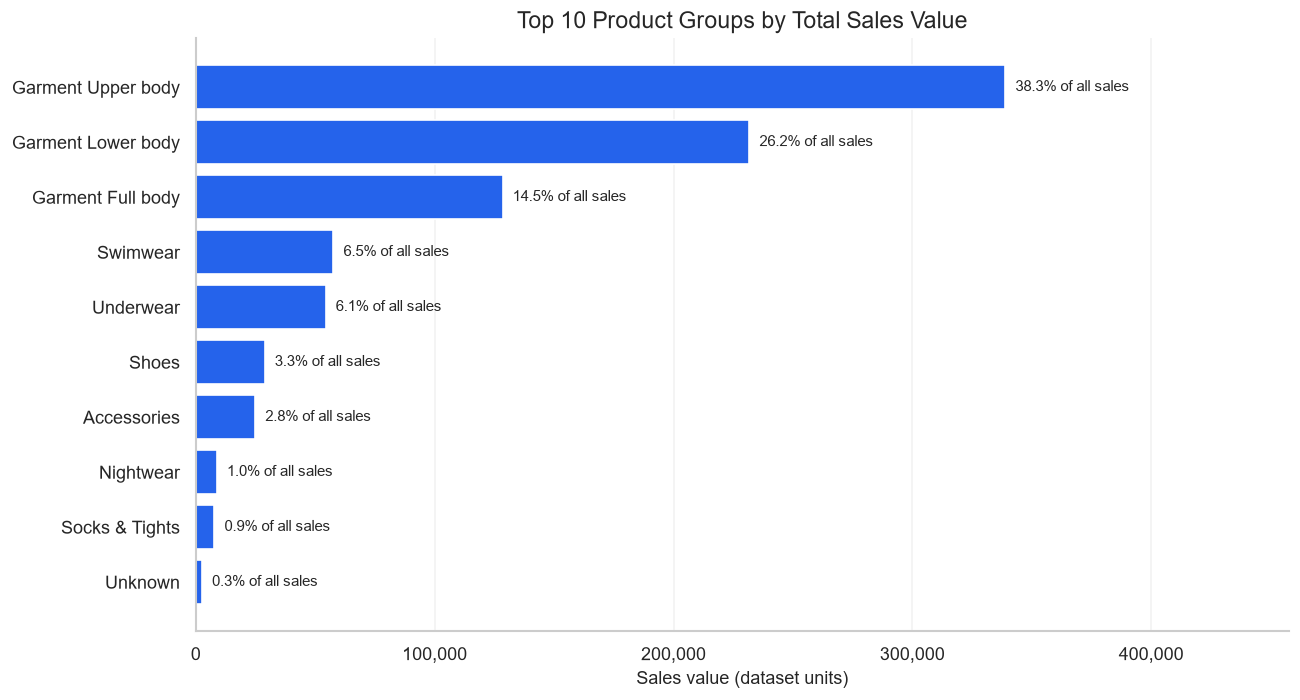

In [32]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Each article ID was verified as unique, so this join preserves rows.
category_sales = con.execute("""
    SELECT
        COALESCE(
            NULLIF(TRIM(a.product_group_name), ''),
            'Unknown'
        ) AS product_group,
        COUNT(*) AS purchase_records,
        SUM(t.price) AS sales_value,
        AVG(t.price) AS average_purchase_price
    FROM transactions AS t
    LEFT JOIN articles AS a
        ON t.article_id = a.article_id
    GROUP BY 1
    ORDER BY sales_value DESC
""").fetchdf()

category_sales["sales_share_pct"] = (
    100 * category_sales["sales_value"]
    / category_sales["sales_value"].sum()
)

category_sales["purchase_share_pct"] = (
    100 * category_sales["purchase_records"]
    / category_sales["purchase_records"].sum()
)

# Verify that every purchase is represented exactly once.
expected_records = int(
    con.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
)

assert int(category_sales["purchase_records"].sum()) == expected_records

display(category_sales.head(10).round({
    "sales_value": 2,
    "average_purchase_price": 5,
    "sales_share_pct": 2,
    "purchase_share_pct": 2,
}))

# Put the largest category at the top.
top_categories = category_sales.head(10).sort_values("sales_value")

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_categories["product_group"],
    top_categories["sales_value"],
    color="#2563EB",
)

for bar, share in zip(bars, top_categories["sales_share_pct"]):
    ax.annotate(
        f"{share:.1f}% of all sales",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

ax.set_xlim(0, top_categories["sales_value"].max() * 1.35)
ax.set_title("Top 10 Product Groups by Total Sales Value")
ax.set_xlabel("Sales value (dataset units)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "14_product_group_sales.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

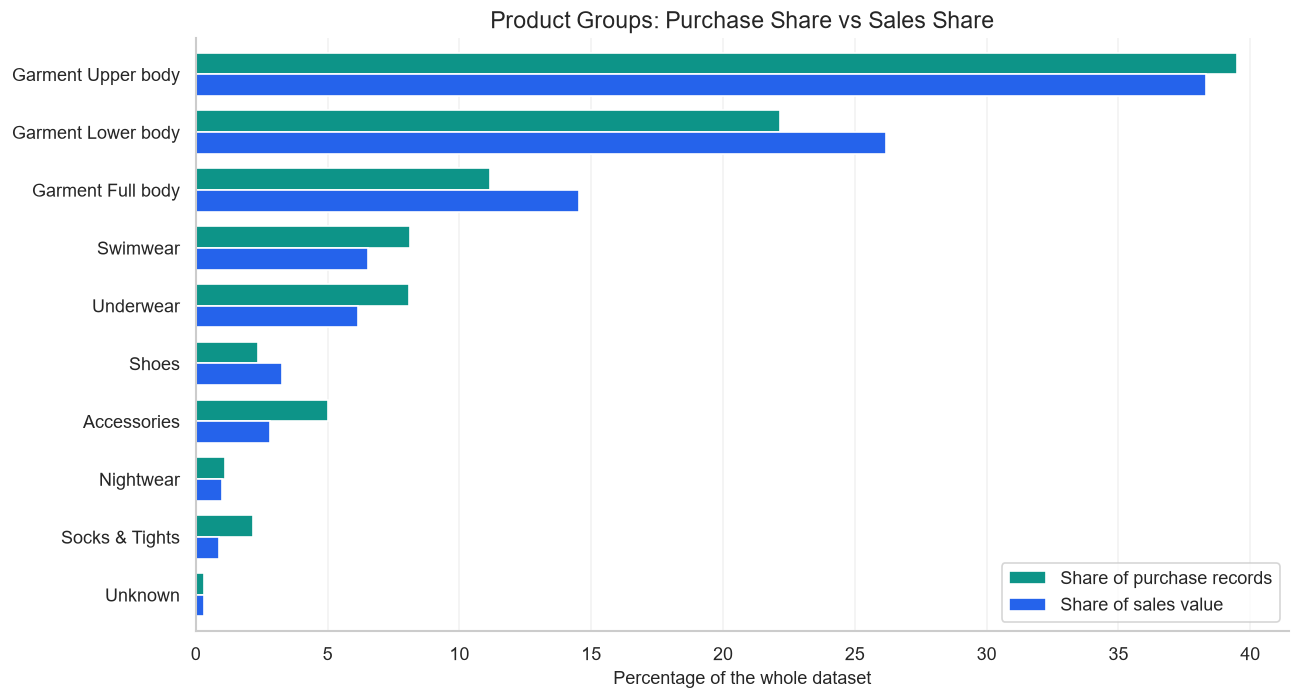

,product_group,purchase_share_pct,sales_share_pct,average_purchase_price
0,Garment Upper body,39.49,38.32,0.02700
1,Garment Lower body,22.17,26.20,0.03289
2,Garment Full body,11.18,14.52,0.03617
3,Swimwear,8.11,6.51,0.02234
4,Underwear,8.07,6.15,0.02120
5,Shoes,2.35,3.27,0.03875
6,Accessories,5.03,2.81,0.01556
7,Nightwear,1.10,1.00,0.02543
8,Socks & Tights,2.16,0.88,0.01139
9,Unknown,0.31,0.29,0.02678


In [33]:
import matplotlib.pyplot as plt

# Compare the same ten categories, ordered by sales value.
category_comparison = (
    category_sales.head(10)
    .set_index("product_group")
    [["purchase_share_pct", "sales_share_pct"]]
    .rename(columns={
        "purchase_share_pct": "Share of purchase records",
        "sales_share_pct": "Share of sales value",
    })
)

ax = category_comparison.plot.barh(
    figsize=(11, 6),
    color=["#0D9488", "#2563EB"],
    width=0.75,
)

ax.invert_yaxis()
ax.set_title("Product Groups: Purchase Share vs Sales Share")
ax.set_xlabel("Percentage of the whole dataset")
ax.set_ylabel("")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig = ax.get_figure()
fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "15_category_purchase_vs_sales_share.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(
    category_sales.head(10)[[
        "product_group",
        "purchase_share_pct",
        "sales_share_pct",
        "average_purchase_price",
    ]].round({
        "purchase_share_pct": 2,
        "sales_share_pct": 2,
        "average_purchase_price": 5,
    })
)

### 10.1 Most Frequently Purchased Product Types

We rank product types by purchase-record count over the full
observation period. These counts represent purchase records,
not distinct orders or unique customers.

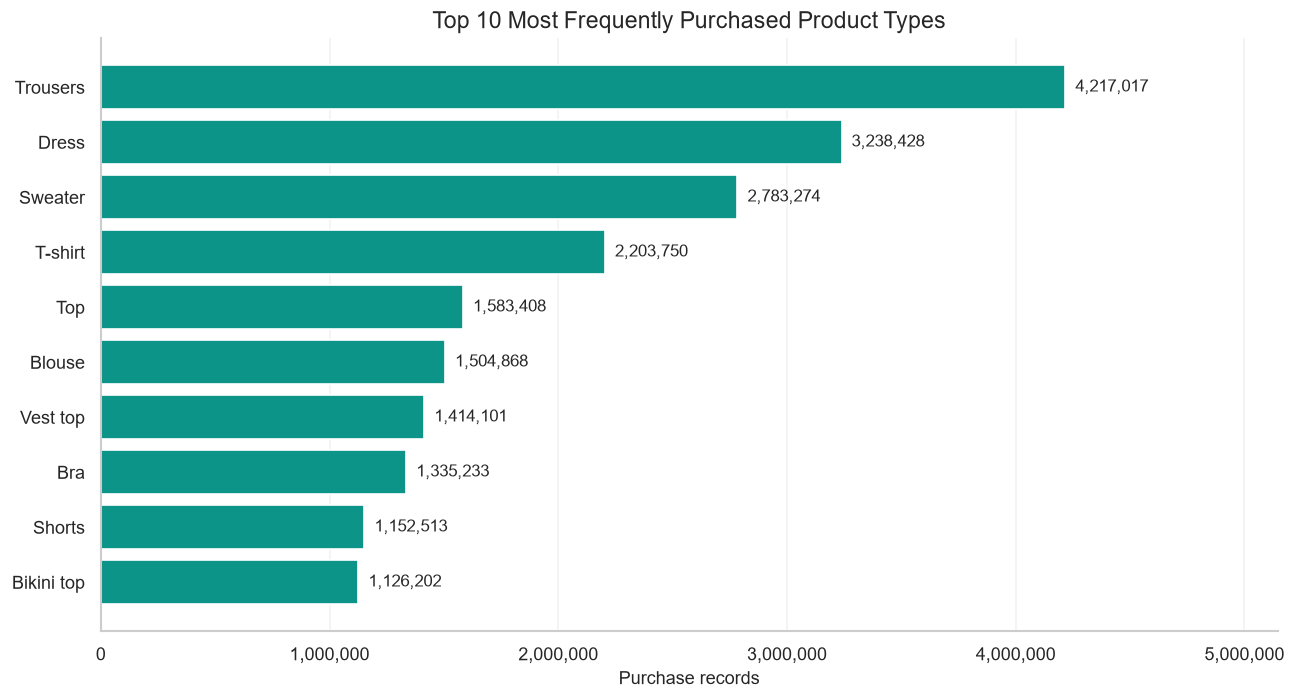

,product_type,purchase_records,sales_value,average_purchase_price,purchase_share_pct
0,Trousers,4217017,150908.05,0.03579,13.27
1,Dress,3238428,118185.80,0.03649,10.19
2,Sweater,2783274,80732.98,0.02901,8.76
3,T-shirt,2203750,30274.88,0.01374,6.93
4,Top,1583408,32120.53,0.02029,4.98
5,Blouse,1504868,42424.63,0.02819,4.73
6,Vest top,1414101,22142.55,0.01566,4.45
7,Bra,1335233,31987.64,0.02396,4.20
8,Shorts,1152513,26973.21,0.02340,3.63
9,Bikini top,1126202,25902.82,0.02300,3.54


In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

product_type_sales = con.execute("""
    SELECT
        COALESCE(
            NULLIF(TRIM(a.product_type_name), ''),
            'Unknown'
        ) AS product_type,
        COUNT(*) AS purchase_records,
        SUM(t.price) AS sales_value,
        AVG(t.price) AS average_purchase_price
    FROM transactions AS t
    LEFT JOIN articles AS a
        ON t.article_id = a.article_id
    GROUP BY 1
    ORDER BY purchase_records DESC, product_type
""").fetchdf()

product_type_sales["purchase_share_pct"] = (
    100 * product_type_sales["purchase_records"]
    / product_type_sales["purchase_records"].sum()
)

top_types = product_type_sales.head(10).sort_values(
    "purchase_records"
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_types["product_type"],
    top_types["purchase_records"],
    color="#0D9488",
)

for bar, count in zip(bars, top_types["purchase_records"]):
    ax.annotate(
        f"{count:,}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
    )

ax.set_xlim(0, top_types["purchase_records"].max() * 1.22)
ax.set_title("Top 10 Most Frequently Purchased Product Types")
ax.set_xlabel("Purchase records")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "16_top_product_types.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(product_type_sales.head(10).round({
    "sales_value": 2,
    "average_purchase_price": 5,
    "purchase_share_pct": 2,
}))

,product_type,purchase_rank,sales_rank,purchase_records,sales_value,average_purchase_price,sales_share_pct
0,Trousers,1,1,4217017,150908.05,0.03579,17.06
1,Dress,2,2,3238428,118185.80,0.03649,13.36
2,Sweater,3,3,2783274,80732.98,0.02901,9.13
5,Blouse,6,4,1504868,42424.63,0.02819,4.80
15,Jacket,16,5,600157,40422.76,0.06735,4.57
12,Skirt,13,6,934338,33230.48,0.03557,3.76
4,Top,5,7,1583408,32120.53,0.02029,3.63
7,Bra,8,8,1335233,31987.64,0.02396,3.62
3,T-shirt,4,9,2203750,30274.88,0.01374,3.42
8,Shorts,9,10,1152513,26973.21,0.02340,3.05


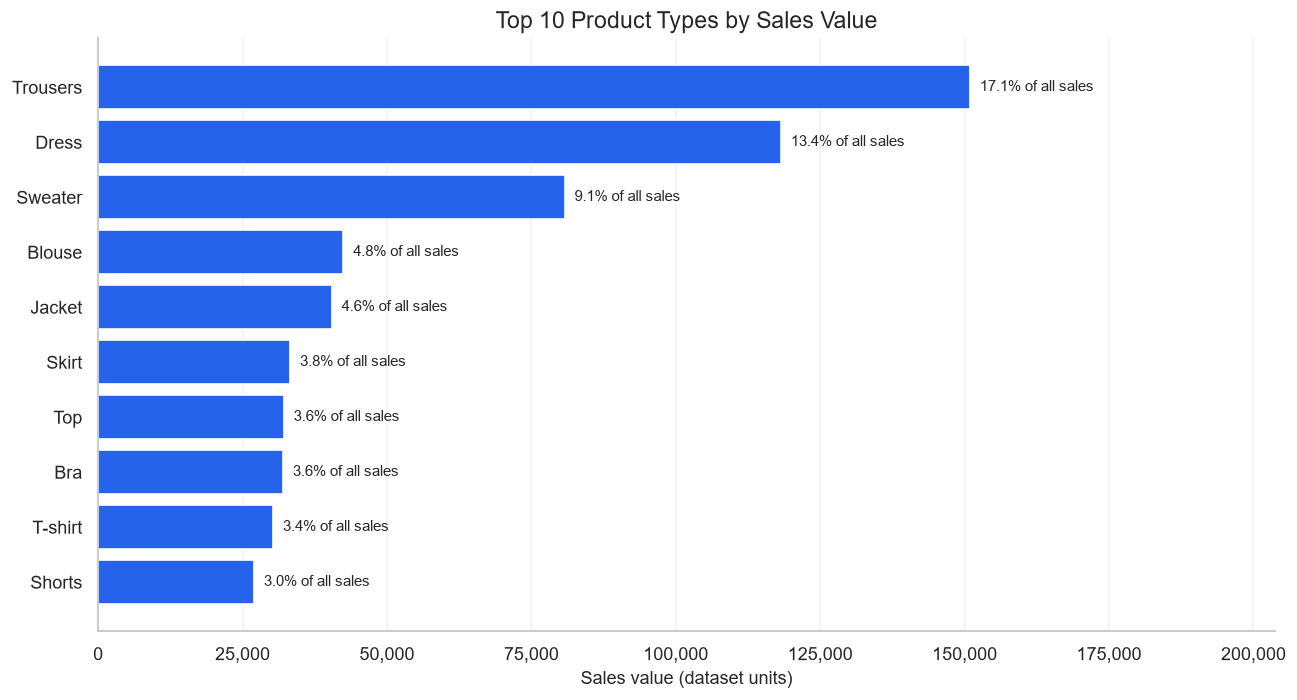

In [35]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Calculate both rankings across all product types.
product_type_rankings = product_type_sales.copy()

product_type_rankings["purchase_rank"] = (
    product_type_rankings["purchase_records"]
    .rank(method="min", ascending=False)
    .astype(int)
)

product_type_rankings["sales_rank"] = (
    product_type_rankings["sales_value"]
    .rank(method="min", ascending=False)
    .astype(int)
)

product_type_rankings["sales_share_pct"] = (
    100 * product_type_rankings["sales_value"]
    / product_type_rankings["sales_value"].sum()
)

# Select the top ten by sales value, independently of purchase rank.
sales_leaders = product_type_rankings.sort_values(
    ["sales_value", "product_type"],
    ascending=[False, True],
).head(10)

display(sales_leaders[[
    "product_type",
    "purchase_rank",
    "sales_rank",
    "purchase_records",
    "sales_value",
    "average_purchase_price",
    "sales_share_pct",
]].round({
    "sales_value": 2,
    "average_purchase_price": 5,
    "sales_share_pct": 2,
}))

plot_data = sales_leaders.sort_values("sales_value")

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_data["product_type"],
    plot_data["sales_value"],
    color="#2563EB",
)

for bar, share in zip(bars, plot_data["sales_share_pct"]):
    ax.annotate(
        f"{share:.1f}% of all sales",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

ax.set_xlim(0, plot_data["sales_value"].max() * 1.35)
ax.set_title("Top 10 Product Types by Sales Value")
ax.set_xlabel("Sales value (dataset units)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "17_top_product_types_sales_value.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## 11. Customer Repeat Purchasing

We distinguish customers with purchases on one observed date from
customers with purchases on multiple dates.

The denominator is customers with at least one observed purchase.
This is a descriptive repeat-purchase measure, not a churn label or
a fixed-period retention rate. Customers have different lengths of
observed purchasing history.

In [36]:
# Build one row per purchasing customer inside DuckDB.
# This temporary table is recreated after a kernel restart.
con.execute("""
    CREATE OR REPLACE TEMP TABLE customer_purchase_summary AS
    SELECT
        customer_id,
        COUNT(*) AS purchase_records,
        SUM(price) AS spending,
        MIN(t_dat) AS first_purchase_date,
        MAX(t_dat) AS last_purchase_date
    FROM transactions
    GROUP BY customer_id
""")

# Return only aggregate results to pandas.
repeat_purchase_summary = con.execute("""
    SELECT
        CASE
            WHEN first_purchase_date = last_purchase_date
                THEN 'One purchase date'
            ELSE 'Multiple purchase dates'
        END AS purchase_pattern,
        COUNT(*) AS customers,
        SUM(purchase_records) AS purchase_records,
        SUM(spending) AS sales_value
    FROM customer_purchase_summary
    GROUP BY 1
""").fetchdf()

repeat_purchase_summary["customer_share_pct"] = (
    100 * repeat_purchase_summary["customers"]
    / repeat_purchase_summary["customers"].sum()
)

repeat_purchase_summary["sales_share_pct"] = (
    100 * repeat_purchase_summary["sales_value"]
    / repeat_purchase_summary["sales_value"].sum()
)

repeat_purchase_summary = (
    repeat_purchase_summary
    .set_index("purchase_pattern")
    .reindex(["One purchase date", "Multiple purchase dates"])
    .fillna(0)
    .reset_index()
)

display(repeat_purchase_summary.round({
    "sales_value": 2,
    "customer_share_pct": 2,
    "sales_share_pct": 2,
}))

,purchase_pattern,customers,purchase_records,sales_value,customer_share_pct,sales_share_pct
0,One purchase date,447973,1550285.0,42137.31,32.88,4.76
1,Multiple purchase dates,914308,30238039.0,842508.66,67.12,95.24


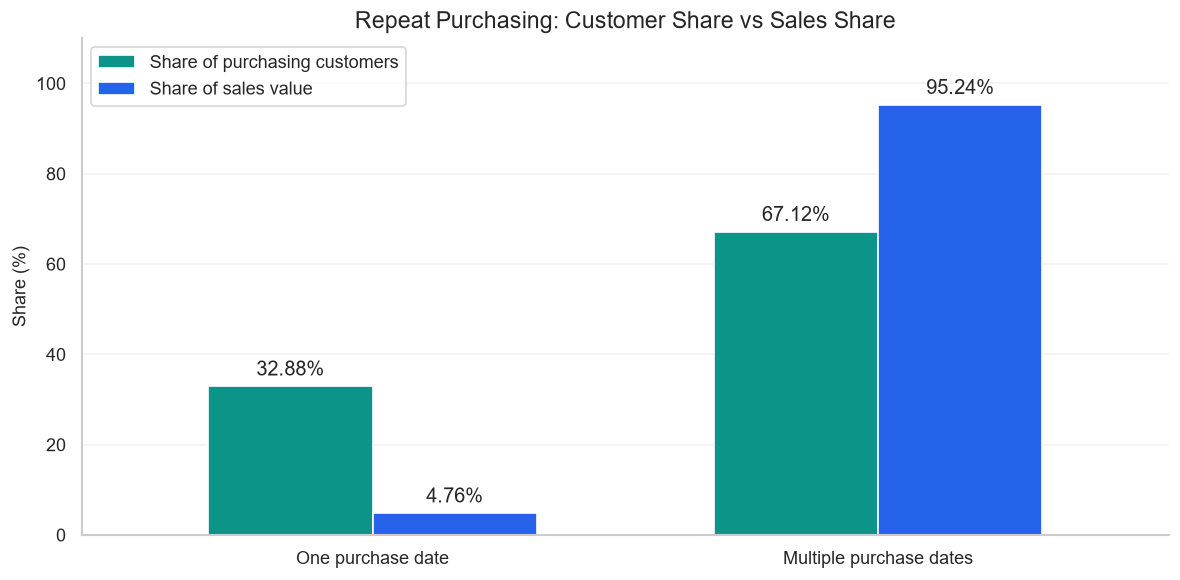

In [37]:
import matplotlib.pyplot as plt

repeat_chart = (
    repeat_purchase_summary
    .set_index("purchase_pattern")
    [["customer_share_pct", "sales_share_pct"]]
    .rename(columns={
        "customer_share_pct": "Share of purchasing customers",
        "sales_share_pct": "Share of sales value",
    })
)

ax = repeat_chart.plot.bar(
    figsize=(10, 5),
    color=["#0D9488", "#2563EB"],
    width=0.65,
    rot=0,
)

# Label every bar with its percentage.
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

ax.set_title("Repeat Purchasing: Customer Share vs Sales Share")
ax.set_xlabel("")
ax.set_ylabel("Share (%)")
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20))
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig = ax.get_figure()
fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "18_repeat_purchase_contribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

Customers purchasing on multiple observed dates represent 67.12%
of purchasing customers and contribute 95.24% of recorded sales value.

This supports further analysis of repeat purchasing and retention.
It does not prove that a retention campaign would increase sales.
The groups have unequal observation periods, and one-date customers
must not automatically be classified as churned.

### 11.1 Customer Spending Concentration

Customers are ranked by total spending during the observation period.
We measure the share of sales contributed by the highest-spending
1%, 5%, 10%, and 20% of purchasing customers.

These are nested groups, so their contributions must not be added.
This describes historical spending, not future customer lifetime value.

In [38]:
# Rank customers inside DuckDB; do not export customer identifiers.
spending_concentration = con.execute("""
    WITH ranked_customers AS (
        SELECT
            spending,
            ROW_NUMBER() OVER (
                ORDER BY spending DESC, customer_id
            ) AS spending_rank
        FROM customer_purchase_summary
    ),
    totals AS (
        SELECT
            COUNT(*) AS total_customers,
            SUM(spending) AS total_spending
        FROM customer_purchase_summary
    ),
    thresholds AS (
        SELECT *
        FROM (VALUES (1), (5), (10), (20)) AS v(top_pct)
    )
    SELECT
        p.top_pct,
        COUNT(*) AS customers_in_group,
        SUM(r.spending) AS group_spending,
        100.0 * SUM(r.spending)
            / MAX(t.total_spending) AS sales_share_pct
    FROM ranked_customers AS r
    CROSS JOIN totals AS t
    CROSS JOIN thresholds AS p
    WHERE r.spending_rank <= CEIL(
        t.total_customers * p.top_pct / 100.0
    )
    GROUP BY p.top_pct
    ORDER BY p.top_pct
""").fetchdf()

display(spending_concentration.round({
    "group_spending": 2,
    "sales_share_pct": 2,
}))

,top_pct,customers_in_group,group_spending,sales_share_pct
0,1,13623,116606.76,13.18
1,5,68115,314450.46,35.55
2,10,136229,452261.05,51.12
3,20,272457,615671.27,69.60


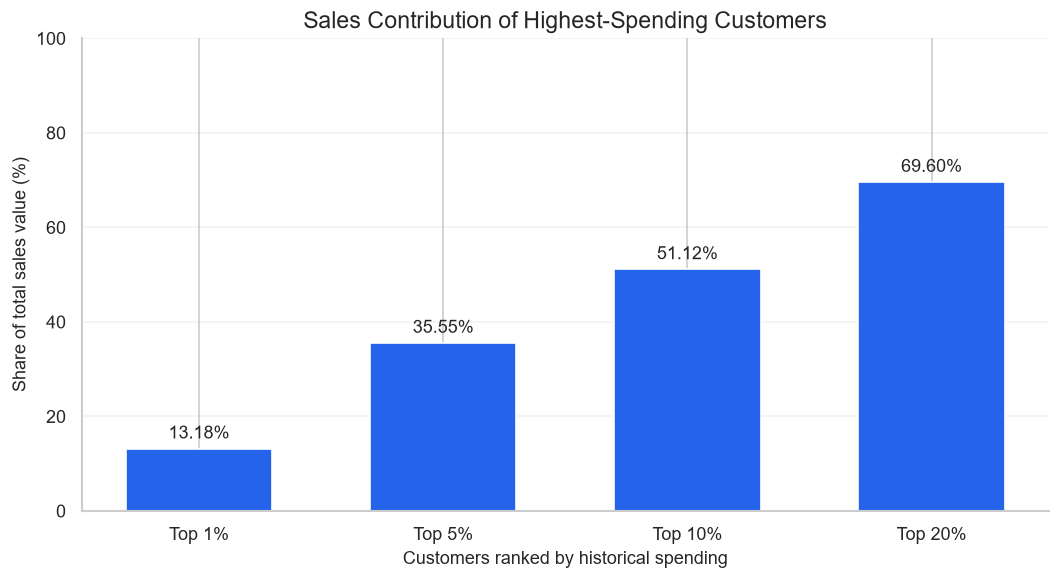

In [39]:
import matplotlib.pyplot as plt

labels = spending_concentration["top_pct"].map(
    lambda value: f"Top {value}%"
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    labels,
    spending_concentration["sales_share_pct"],
    color="#2563EB",
    width=0.6,
)

for bar, share in zip(
    bars, spending_concentration["sales_share_pct"]
):
    ax.annotate(
        f"{share:.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=11,
    )

ax.set_ylim(0, 100)
ax.set_title("Sales Contribution of Highest-Spending Customers")
ax.set_xlabel("Customers ranked by historical spending")
ax.set_ylabel("Share of total sales value (%)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "19_customer_spending_concentration.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

The top 10% of purchasing customers contribute 51.12% of sales value,
while the top 20% contribute 69.60%. Spending is strongly concentrated,
although it does not follow an exact 80/20 pattern.

These groups reflect spending over the observed period. Customers
have different observation lengths, and historical spending should
not be interpreted as future lifetime value.

In [40]:
# Anchor recency to the end of the available transaction history.
analysis_date = con.execute(
    "SELECT MAX(t_dat) FROM transactions"
).fetchone()[0]

recency_summary = con.execute("""
    WITH customer_recency AS (
        SELECT
            DATE_DIFF(
                'day',
                last_purchase_date,
                CAST(? AS DATE)
            ) AS days_since_last_purchase
        FROM customer_purchase_summary
    ),
    grouped AS (
        SELECT
            CASE
                WHEN days_since_last_purchase <= 30 THEN 1
                WHEN days_since_last_purchase <= 60 THEN 2
                WHEN days_since_last_purchase <= 90 THEN 3
                WHEN days_since_last_purchase <= 180 THEN 4
                WHEN days_since_last_purchase <= 365 THEN 5
                ELSE 6
            END AS group_order,
            CASE
                WHEN days_since_last_purchase <= 30 THEN '0–30 days'
                WHEN days_since_last_purchase <= 60 THEN '31–60 days'
                WHEN days_since_last_purchase <= 90 THEN '61–90 days'
                WHEN days_since_last_purchase <= 180 THEN '91–180 days'
                WHEN days_since_last_purchase <= 365 THEN '181–365 days'
                ELSE '366+ days'
            END AS recency_group
        FROM customer_recency
    )
    SELECT
        group_order,
        recency_group,
        COUNT(*) AS customers
    FROM grouped
    GROUP BY 1, 2
    ORDER BY 1
""", [analysis_date]).fetchdf()

recency_summary["customer_share_pct"] = (
    100 * recency_summary["customers"]
    / recency_summary["customers"].sum()
)

print("Recency measured as of:", analysis_date)

display(
    recency_summary[
        ["recency_group", "customers", "customer_share_pct"]
    ].round({"customer_share_pct": 2})
)

Recency measured as of: 2020-09-22


,recency_group,customers,customer_share_pct
0,0–30 days,250619,18.40
1,31–60 days,149839,11.00
2,61–90 days,124617,9.15
3,91–180 days,217356,15.96
4,181–365 days,251889,18.49
5,366+ days,367961,27.01


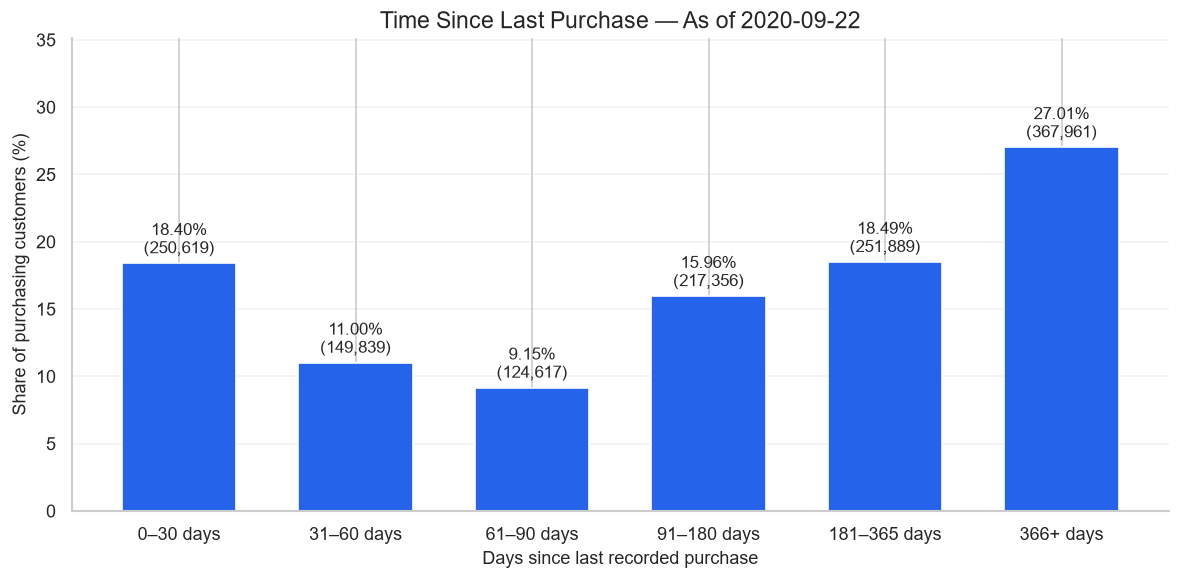

In [41]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    recency_summary["recency_group"],
    recency_summary["customer_share_pct"],
    color="#2563EB",
    width=0.65,
)

for bar, count, share in zip(
    bars,
    recency_summary["customers"],
    recency_summary["customer_share_pct"],
):
    ax.annotate(
        f"{share:.2f}%\n({int(count):,})",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_ylim(
    0,
    recency_summary["customer_share_pct"].max() * 1.3,
)
ax.set_title(f"Time Since Last Purchase — As of {analysis_date}")
ax.set_xlabel("Days since last recorded purchase")
ax.set_ylabel("Share of purchasing customers (%)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "20_customer_purchase_recency.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

As of 22 September 2020, approximately 61.46% of purchasing customers
had not purchased within the previous 0–90-day recency band.
The 366+ day group represented 27.01%.

These are descriptive inactivity groups, not confirmed churn labels.
The bands have unequal widths, and purchases after the dataset's
end are unobserved.

### 11.2 Time Between Purchase Dates

We calculate days between consecutive distinct purchase dates for
each customer. Same-day purchases are combined only for calculating
these intervals; the original transactions remain unchanged.

Only completed, observed gaps are included. Customers who purchase
frequently contribute more gaps. Waiting time after a customer's
final purchase is not included, so this is not a return-probability
estimate for all customers.

In [42]:
# Keep customer-level calculations inside DuckDB.
con.execute("""
    CREATE OR REPLACE TEMP TABLE customer_purchase_gaps AS
    WITH purchase_dates AS (
        SELECT DISTINCT customer_id, t_dat
        FROM transactions
    ),
    previous_dates AS (
        SELECT
            customer_id,
            t_dat,
            LAG(t_dat) OVER (
                PARTITION BY customer_id
                ORDER BY t_dat
            ) AS previous_purchase_date
        FROM purchase_dates
    )
    SELECT
        customer_id,
        DATE_DIFF(
            'day',
            previous_purchase_date,
            t_dat
        ) AS gap_days
    FROM previous_dates
    WHERE previous_purchase_date IS NOT NULL
""")

# Summarize observed intervals.
purchase_gap_summary = con.execute("""
    SELECT
        COUNT(*) AS completed_gaps,
        COUNT(DISTINCT customer_id) AS customers_with_gaps,
        MIN(gap_days) AS minimum_days,
        AVG(gap_days) AS mean_days,
        MEDIAN(gap_days) AS median_days,
        QUANTILE_CONT(gap_days, 0.75) AS p75_days,
        QUANTILE_CONT(gap_days, 0.90) AS p90_days,
        QUANTILE_CONT(gap_days, 0.95) AS p95_days,
        MAX(gap_days) AS maximum_days,
        100.0 * COUNT(*) FILTER (WHERE gap_days <= 30)
            / NULLIF(COUNT(*), 0) AS gaps_within_30_days_pct,
        100.0 * COUNT(*) FILTER (WHERE gap_days <= 60)
            / NULLIF(COUNT(*), 0) AS gaps_within_60_days_pct,
        100.0 * COUNT(*) FILTER (WHERE gap_days <= 90)
            / NULLIF(COUNT(*), 0) AS gaps_within_90_days_pct
    FROM customer_purchase_gaps
""").fetchdf()

display(
    purchase_gap_summary.T
    .rename(columns={0: "Value"})
    .round(2)
)

# Small frequency table for the next graph.
purchase_gap_distribution = con.execute("""
    SELECT
        gap_days,
        COUNT(*) AS gap_count
    FROM customer_purchase_gaps
    GROUP BY gap_days
    ORDER BY gap_days
""").fetchdf()

,Value
completed_gaps,7717898.00
customers_with_gaps,914308.00
minimum_days,1.00
mean_days,48.26
median_days,22.00
p75_days,58.00
p90_days,124.00
p95_days,187.00
maximum_days,731.00
gaps_within_30_days_pct,58.47


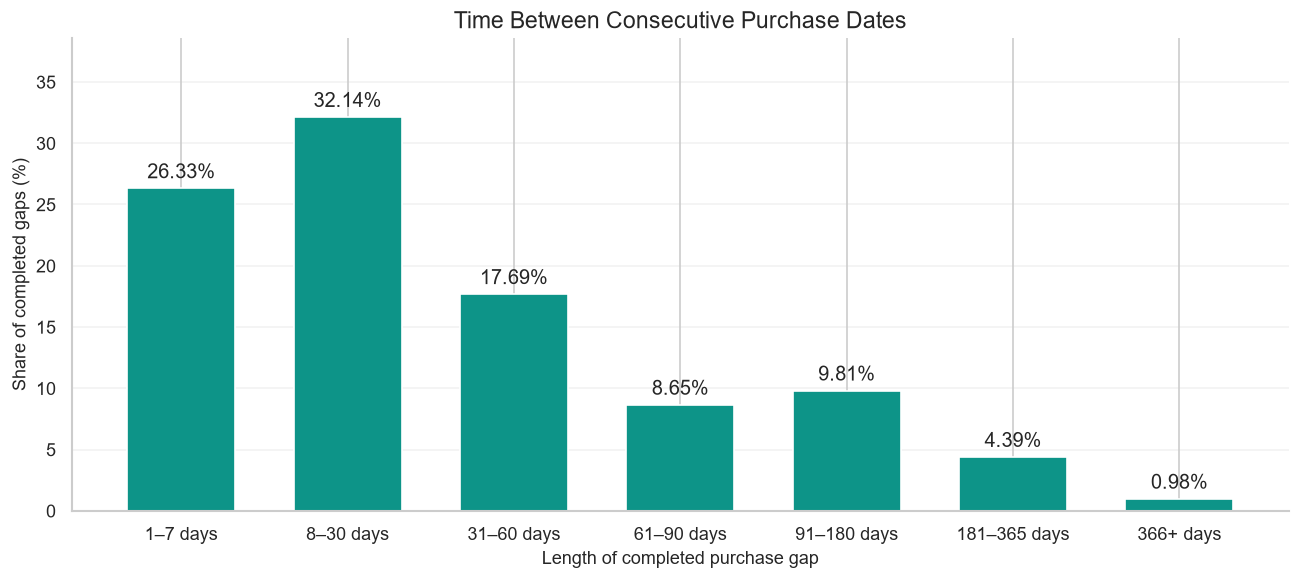

,interval,gap_count,gap_share_pct
0,1–7 days,2031761,26.33
1,8–30 days,2480808,32.14
2,31–60 days,1364950,17.69
3,61–90 days,667887,8.65
4,91–180 days,757399,9.81
5,181–365 days,339176,4.39
6,366+ days,75917,0.98


In [43]:
import pandas as pd
import matplotlib.pyplot as plt

gap_groups = purchase_gap_distribution.copy()

labels = [
    "1–7 days",
    "8–30 days",
    "31–60 days",
    "61–90 days",
    "91–180 days",
    "181–365 days",
    "366+ days",
]

gap_groups["interval"] = pd.cut(
    gap_groups["gap_days"],
    bins=[0, 7, 30, 60, 90, 180, 365, float("inf")],
    labels=labels,
    right=True,
)

gap_group_summary = (
    gap_groups.groupby("interval", observed=False)["gap_count"]
    .sum()
    .reindex(labels, fill_value=0)
    .reset_index()
)

gap_group_summary["gap_share_pct"] = (
    100 * gap_group_summary["gap_count"]
    / gap_group_summary["gap_count"].sum()
)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    gap_group_summary["interval"].astype(str),
    gap_group_summary["gap_share_pct"],
    color="#0D9488",
    width=0.65,
)

for bar, share in zip(bars, gap_group_summary["gap_share_pct"]):
    ax.annotate(
        f"{share:.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
    )

ax.set_ylim(0, gap_group_summary["gap_share_pct"].max() * 1.2)
ax.set_title("Time Between Consecutive Purchase Dates")
ax.set_xlabel("Length of completed purchase gap")
ax.set_ylabel("Share of completed gaps (%)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "21_purchase_gap_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(gap_group_summary.round({"gap_share_pct": 2}))


Across 7,717,898 completed gaps from 914,308 repeat purchasers,
the median interval was 22 days and the mean was 48.26 days.
Of these gaps, 15.19% exceeded 90 days before another purchase occurred.

Completed gaps exclude ongoing waiting times after final purchases
and give more weight to frequent purchasers. They cannot directly
estimate the probability that an arbitrary customer will return.

## 12. Monthly Cohort Retention

A cohort contains customers whose first observed purchase falls in
the same calendar month.

Month 0 is their first observed purchase month. Month 1 is the next
calendar month, not a fixed 30-day period.

Retention is the percentage of the original cohort purchasing in
a particular later month. Customers may skip months and return.

First observed purchase does not necessarily mean first-ever purchase.
We exclude the partial September 2018 starting cohort and stop
follow-up at August 2020, the final fully observed month.
Unobserved future months must remain blank rather than zero.

In [44]:
# Assign cohorts using each customer's first purchase in the FULL history.
# Filtering happens afterward, so earlier customers are not relabeled.
con.execute("""
    CREATE OR REPLACE TEMP TABLE customer_cohorts AS
    SELECT
        customer_id,
        DATE_TRUNC('month', first_purchase_date)::DATE AS cohort_month
    FROM customer_purchase_summary
    WHERE first_purchase_date >= DATE '2018-10-01'
      AND first_purchase_date < DATE '2020-09-01'
""")

# Count each customer once per calendar month.
con.execute("""
    CREATE OR REPLACE TEMP TABLE cohort_month_activity AS
    SELECT DISTINCT
        c.customer_id,
        c.cohort_month,
        DATE_TRUNC('month', t.t_dat)::DATE AS activity_month
    FROM transactions AS t
    INNER JOIN customer_cohorts AS c
        ON t.customer_id = c.customer_id
    WHERE t.t_dat >= DATE '2018-10-01'
      AND t.t_dat < DATE '2020-09-01'
""")

cohort_retention = con.execute("""
    WITH cohort_sizes AS (
        SELECT
            cohort_month,
            COUNT(*) AS cohort_customers
        FROM customer_cohorts
        GROUP BY cohort_month
    ),
    activity_counts AS (
        SELECT
            cohort_month,
            activity_month,
            COUNT(*) AS purchasing_customers
        FROM cohort_month_activity
        GROUP BY cohort_month, activity_month
    ),
    observable_months AS (
        SELECT
            s.cohort_month,
            s.cohort_customers,
            m.activity_month::DATE AS activity_month
        FROM cohort_sizes AS s
        CROSS JOIN LATERAL GENERATE_SERIES(
            s.cohort_month,
            DATE '2020-08-01',
            INTERVAL '1 month'
        ) AS m(activity_month)
    )
    SELECT
        o.cohort_month,
        DATE_DIFF(
            'month', o.cohort_month, o.activity_month
        ) AS month_number,
        o.cohort_customers,
        COALESCE(a.purchasing_customers, 0) AS purchasing_customers,
        100.0 * COALESCE(a.purchasing_customers, 0)
            / o.cohort_customers AS retention_pct
    FROM observable_months AS o
    LEFT JOIN activity_counts AS a
        ON o.cohort_month = a.cohort_month
       AND o.activity_month = a.activity_month
    ORDER BY o.cohort_month, month_number
""").fetchdf()

# Month 0 must include every member of its cohort.
month_zero = cohort_retention.query("month_number == 0")

assert (
    month_zero["purchasing_customers"]
    == month_zero["cohort_customers"]
).all(), "Month 0 counts do not match cohort sizes."

# Preview the first three cohorts and their first four months.
first_cohorts = sorted(cohort_retention["cohort_month"].unique())[:3]

preview = cohort_retention.loc[
    cohort_retention["cohort_month"].isin(first_cohorts)
    & (cohort_retention["month_number"] <= 3)
]

display(preview.round({"retention_pct": 2}))

,cohort_month,month_number,cohort_customers,purchasing_customers,retention_pct
0,2018-10-01,0,212669,212669,100.00
1,2018-10-01,1,212669,76181,35.82
2,2018-10-01,2,212669,70927,33.35
3,2018-10-01,3,212669,67367,31.68
23,2018-11-01,0,138233,138233,100.00
24,2018-11-01,1,138233,36452,26.37
25,2018-11-01,2,138233,33057,23.91
26,2018-11-01,3,138233,30717,22.22
45,2018-12-01,0,89944,89944,100.00
46,2018-12-01,1,89944,18960,21.08


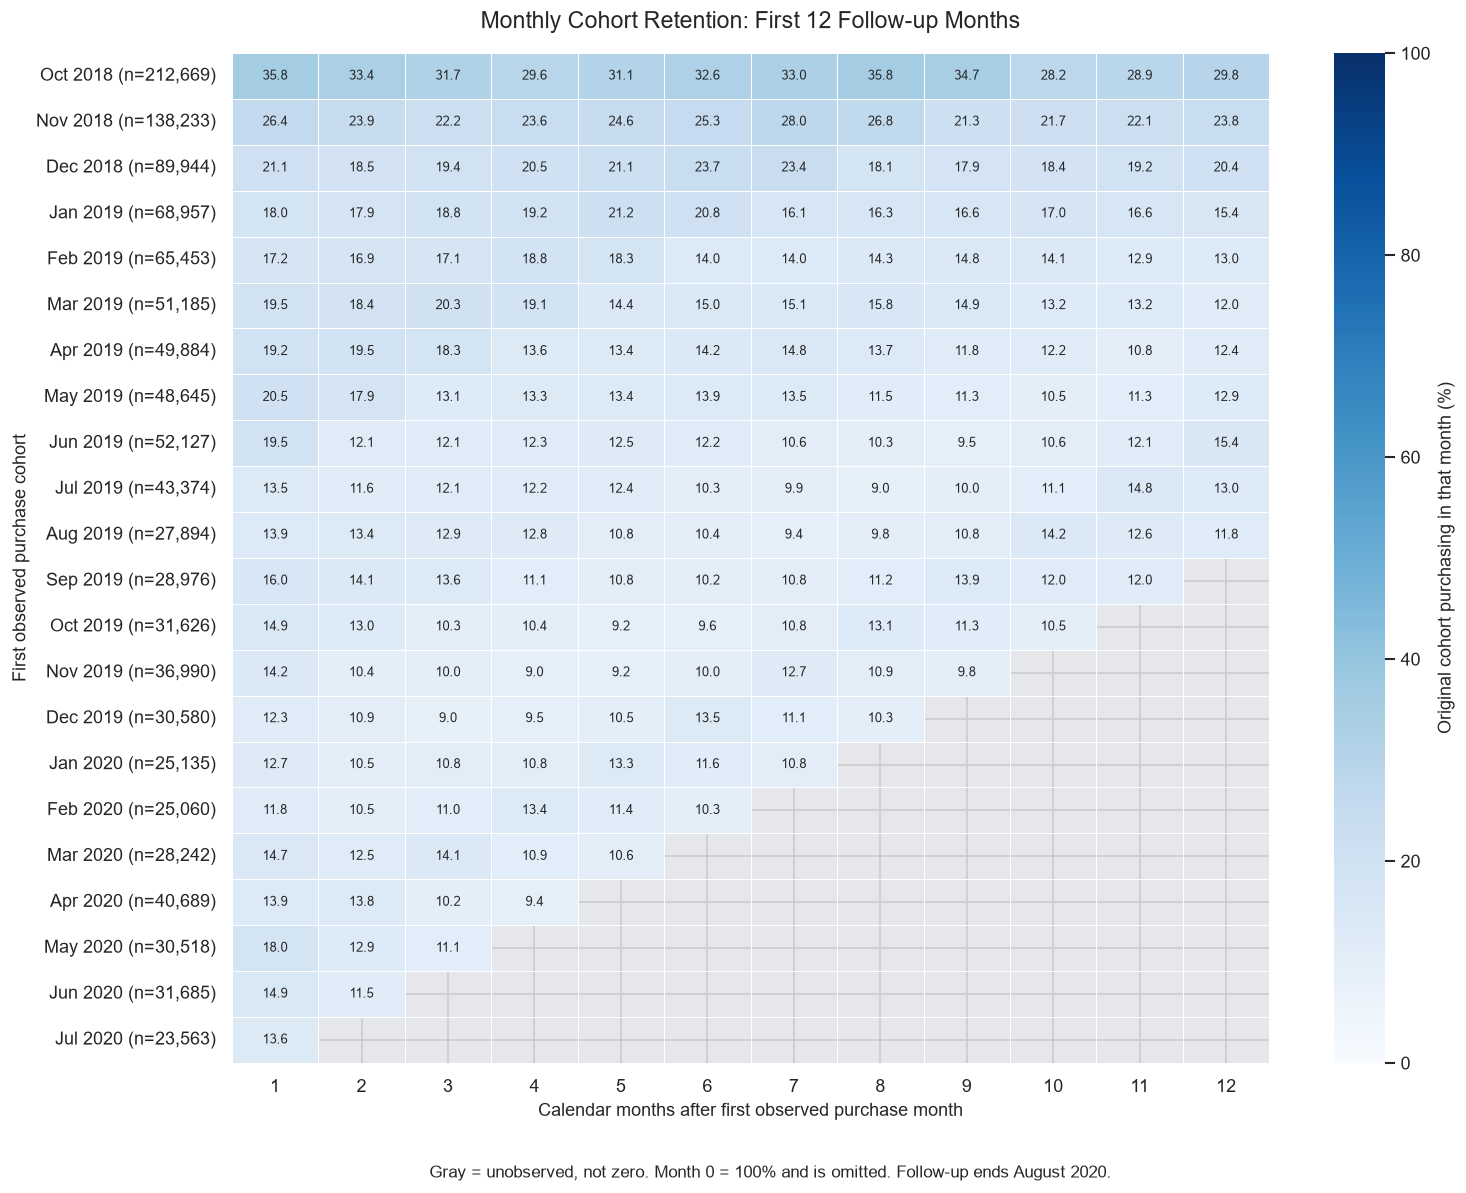

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape the calculated results.
# Missing future months stay NaN; do not fill them with zero.
retention_matrix = cohort_retention.pivot(
    index="cohort_month",
    columns="month_number",
    values="retention_pct",
).sort_index()

heatmap_data = retention_matrix.reindex(columns=range(1, 13))

# Exclude cohorts with no observed follow-up month.
heatmap_data = heatmap_data.dropna(how="all")

cohort_sizes = (
    cohort_retention.loc[
        cohort_retention["month_number"] == 0
    ]
    .set_index("cohort_month")["cohort_customers"]
)

row_labels = [
    f"{pd.Timestamp(month):%b %Y} (n={int(cohort_sizes.loc[month]):,})"
    for month in heatmap_data.index
]

fig, ax = plt.subplots(figsize=(13, 10))

# Gray cells represent follow-up months outside our observation period.
ax.set_facecolor("#E5E7EB")

sns.heatmap(
    heatmap_data,
    mask=heatmap_data.isna(),
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.4,
    linecolor="white",
    annot_kws={"fontsize": 8},
    yticklabels=row_labels,
    cbar_kws={"label": "Original cohort purchasing in that month (%)"},
    ax=ax,
)

ax.set_title("Monthly Cohort Retention: First 12 Follow-up Months", pad=15)
ax.set_xlabel("Calendar months after first observed purchase month")
ax.set_ylabel("First observed purchase cohort")
ax.tick_params(axis="y", rotation=0)

fig.text(
    0.5, 0.01,
    "Gray = unobserved, not zero. Month 0 = 100% and is omitted. "
    "Follow-up ends August 2020.",
    ha="center",
    fontsize=10,
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "22_monthly_cohort_retention.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

Monthly purchasing is intermittent: several cohorts show increases
after periods of lower activity. For example, the June 2019 cohort
rises from 9.5% in Month 9 to 15.4% in Month 12.

Early cohorts have higher observed retention, but first-observed
cohorts are not necessarily newly acquired customers. Differences
may reflect customer composition, seasonality, and observation limits.
Missing future months are excluded from interpretation.

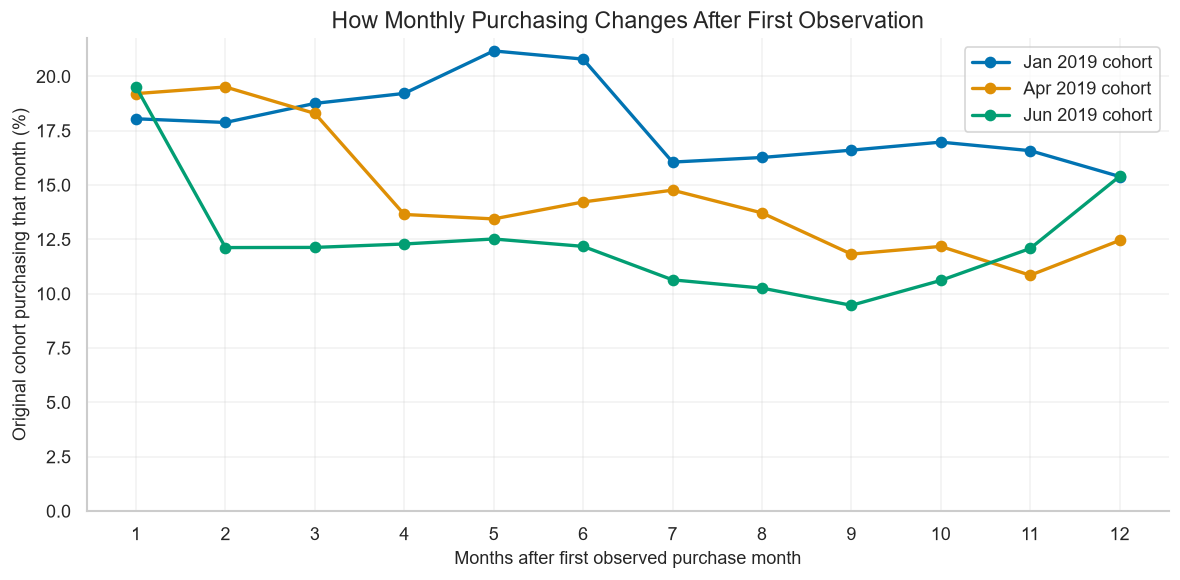

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

selected_cohorts = [
    pd.Timestamp("2019-01-01"),
    pd.Timestamp("2019-04-01"),
    pd.Timestamp("2019-06-01"),
]

fig, ax = plt.subplots(figsize=(10, 5))

for cohort in selected_cohorts:
    cohort_data = cohort_retention.loc[
        (pd.to_datetime(cohort_retention["cohort_month"]) == cohort)
        & cohort_retention["month_number"].between(1, 12)
    ].sort_values("month_number")

    ax.plot(
        cohort_data["month_number"],
        cohort_data["retention_pct"],
        marker="o",
        linewidth=2,
        label=f"{cohort:%b %Y} cohort",
    )

ax.set_title("How Monthly Purchasing Changes After First Observation")
ax.set_xlabel("Months after first observed purchase month")
ax.set_ylabel("Original cohort purchasing that month (%)")
ax.set_xticks(range(1, 13))
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "23_selected_cohort_retention.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


## 13. RFM Customer Analysis

We calculate recency, distinct purchase-day frequency, and spending
for customers with at least one observed purchase.

Recency is measured at the dataset's final date. Frequency counts
purchase dates because order IDs are unavailable. Monetary values
are expressed in dataset units.

These are descriptive full-history measures. They are not yet
features prepared for a historical prediction model.

In [47]:
analysis_date = con.execute(
    "SELECT MAX(t_dat) FROM transactions"
).fetchone()[0]

# Each customer has one fewer completed gap than purchase dates.
# Reuse the gap table rather than regrouping all transaction dates.
con.execute("""
    CREATE OR REPLACE TEMP TABLE customer_rfm AS
    WITH gap_counts AS (
        SELECT
            customer_id,
            COUNT(*) AS completed_gaps
        FROM customer_purchase_gaps
        GROUP BY customer_id
    )
    SELECT
        c.customer_id,

        DATE_DIFF(
            'day',
            c.last_purchase_date,
            CAST(? AS DATE)
        ) AS recency_days,

        COALESCE(g.completed_gaps, 0) + 1 AS frequency_days,

        c.spending AS monetary_value,

        DATE_DIFF(
            'day',
            c.first_purchase_date,
            CAST(? AS DATE)
        ) + 1 AS observed_history_days

    FROM customer_purchase_summary AS c
    LEFT JOIN gap_counts AS g
        ON c.customer_id = g.customer_id
""", [analysis_date, analysis_date])

# Display aggregate statistics without exposing customer IDs.
rfm_summary_rows = []

for column, label in [
    ("recency_days", "Recency (days)"),
    ("frequency_days", "Frequency (purchase days)"),
    ("monetary_value", "Spending (dataset units)"),
    ("observed_history_days", "Days since first observation (inclusive)"),
]:
    result = con.execute(f"""
        SELECT
            MIN({column}),
            QUANTILE_CONT({column}, 0.25),
            MEDIAN({column}),
            AVG({column}),
            QUANTILE_CONT({column}, 0.75),
            QUANTILE_CONT({column}, 0.95),
            MAX({column})
        FROM customer_rfm
    """).fetchone()

    rfm_summary_rows.append({
        "Measure": label,
        "Minimum": result[0],
        "Q1": result[1],
        "Median": result[2],
        "Mean": result[3],
        "Q3": result[4],
        "P95": result[5],
        "Maximum": result[6],
    })

rfm_summary = pd.DataFrame(rfm_summary_rows)

print("RFM analysis date:", analysis_date)
display(rfm_summary.round(4))


RFM analysis date: 2020-09-22


,Measure,Minimum,Q1,Median,Mean,Q3,P95,Maximum
0,Recency (days),0.0000,48.0000,151.0000,235.1484,398.0000,673.0000,733.0000
1,Frequency (purchase days),1.0000,1.0000,3.0000,6.6654,8.0000,24.0000,427.0000
2,Spending (dataset units),0.0008,0.0881,0.2456,0.6494,0.7012,2.5735,57.6764
3,Days since first observation (inclusive),1.0000,356.0000,585.0000,509.5392,695.0000,728.0000,734.0000


In [48]:
# Calculate exact thresholds rather than copying rounded display values.
frequency_q3, spending_q3 = con.execute("""
    SELECT
        QUANTILE_CONT(frequency_days, 0.75),
        QUANTILE_CONT(monetary_value, 0.75)
    FROM customer_rfm
""").fetchone()

recency_boundary = 90

print("Recency boundary:", recency_boundary, "days")
print("Frequency Q3:", frequency_q3, "purchase days")
print("Spending Q3:", f"{spending_q3:.8f}", "dataset units")

# Assign descriptive groups; do not label anyone as confirmed churned.
con.execute("""
    CREATE OR REPLACE TEMP TABLE customer_rfm_segments AS
    SELECT
        *,
        CASE
            WHEN recency_days <= ? THEN '0–90 days'
            ELSE 'Over 90 days'
        END AS recency_group,
        CASE
            WHEN frequency_days >= ? THEN 'Higher frequency'
            ELSE 'Lower frequency'
        END AS frequency_group,
        CASE
            WHEN monetary_value >= ? THEN 'Higher spending'
            ELSE 'Lower spending'
        END AS spending_group
    FROM customer_rfm
""", [recency_boundary, frequency_q3, spending_q3])

rfm_segment_summary = con.execute("""
    SELECT
        recency_group,
        frequency_group,
        spending_group,
        COUNT(*) AS customers,
        SUM(monetary_value) AS historical_sales_value,
        MEDIAN(recency_days) AS median_recency_days,
        MEDIAN(frequency_days) AS median_purchase_days,
        MEDIAN(observed_history_days) AS median_history_days
    FROM customer_rfm_segments
    GROUP BY 1, 2, 3
    ORDER BY historical_sales_value DESC
""").fetchdf()

rfm_segment_summary["customer_share_pct"] = (
    100 * rfm_segment_summary["customers"]
    / rfm_segment_summary["customers"].sum()
)

rfm_segment_summary["sales_share_pct"] = (
    100 * rfm_segment_summary["historical_sales_value"]
    / rfm_segment_summary["historical_sales_value"].sum()
)

display(rfm_segment_summary.round({
    "historical_sales_value": 2,
    "customer_share_pct": 2,
    "sales_share_pct": 2,
}))

Recency boundary: 90 days
Frequency Q3: 8.0 purchase days
Spending Q3: 0.70118644 dataset units


,recency_group,frequency_group,spending_group,customers,historical_sales_value,median_recency_days,median_purchase_days,median_history_days,customer_share_pct,sales_share_pct
0,0–90 days,Higher frequency,Higher spending,224185,509743.20,24.0,18.0,704.0,16.46,57.62
1,Over 90 days,Lower frequency,Lower spending,715656,118693.23,361.0,1.0,526.0,52.53,13.42
2,Over 90 days,Higher frequency,Higher spending,56419,93594.20,151.0,12.0,703.0,4.14,10.58
3,0–90 days,Lower frequency,Lower spending,217927,52027.22,42.0,3.0,271.0,16.00,5.88
4,Over 90 days,Lower frequency,Higher spending,35979,39705.45,221.0,5.0,642.0,2.64,4.49
5,0–90 days,Higher frequency,Lower spending,58970,29963.89,36.0,10.0,664.0,4.33,3.39
6,0–90 days,Lower frequency,Higher spending,23993,26553.73,38.0,6.0,570.0,1.76,3.00
7,Over 90 days,Higher frequency,Lower spending,29152,14365.05,190.0,9.0,689.0,2.14,1.62


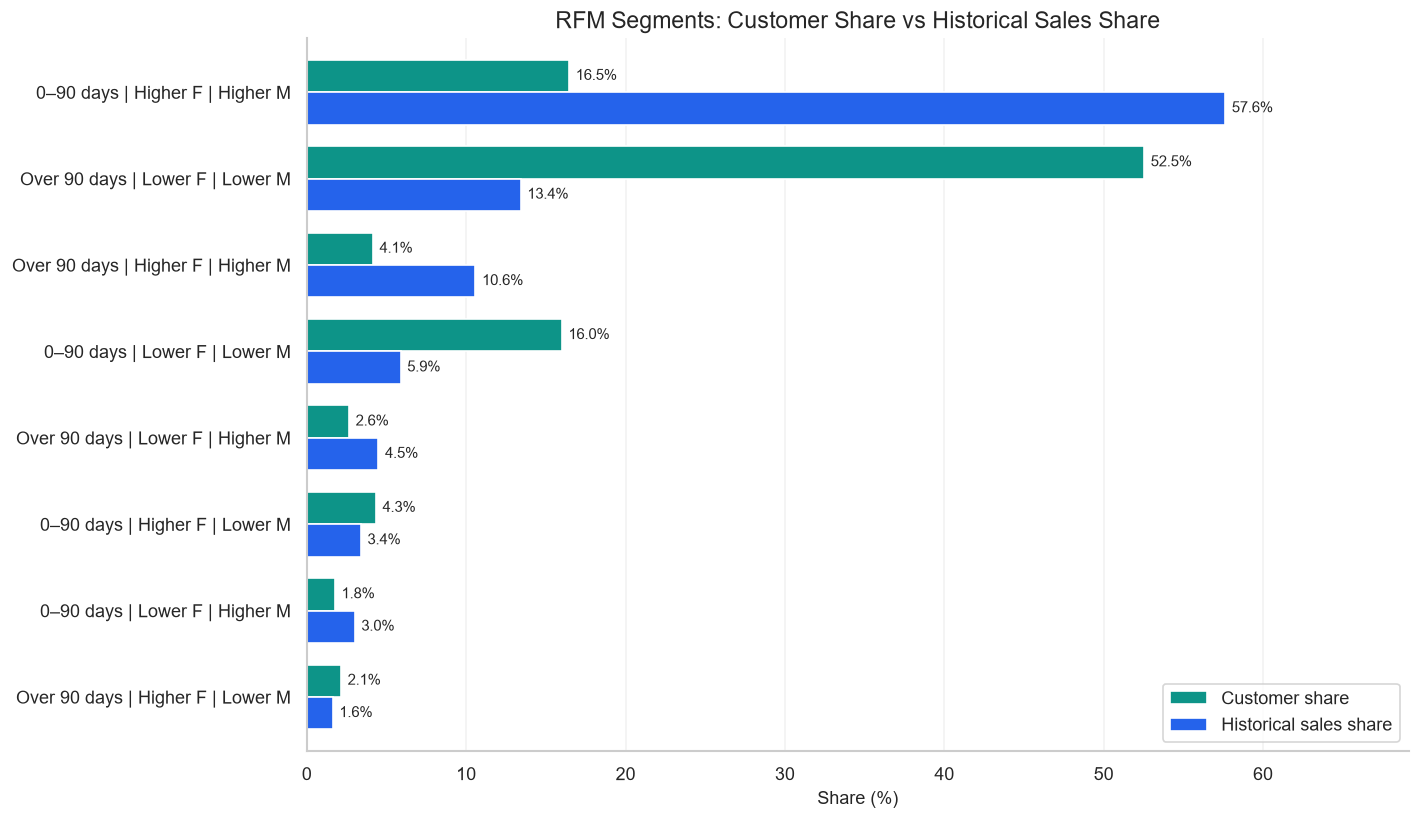

In [49]:
import matplotlib.pyplot as plt

segment_plot = rfm_segment_summary.copy()

segment_plot["Segment"] = (
    segment_plot["recency_group"]
    + " | "
    + segment_plot["frequency_group"].replace({
        "Higher frequency": "Higher F",
        "Lower frequency": "Lower F",
    })
    + " | "
    + segment_plot["spending_group"].replace({
        "Higher spending": "Higher M",
        "Lower spending": "Lower M",
    })
)

segment_plot = segment_plot.sort_values(
    "sales_share_pct", ascending=False
)

chart_data = segment_plot.set_index("Segment")[[
    "customer_share_pct",
    "sales_share_pct",
]].rename(columns={
    "customer_share_pct": "Customer share",
    "sales_share_pct": "Historical sales share",
})

ax = chart_data.plot.barh(
    figsize=(12, 7),
    color=["#0D9488", "#2563EB"],
    width=0.75,
)

ax.invert_yaxis()

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=9)

ax.set_xlim(0, chart_data.to_numpy().max() * 1.2)
ax.set_title("RFM Segments: Customer Share vs Historical Sales Share")
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig = ax.get_figure()
fig.tight_layout()

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "24_rfm_segment_contribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

Recent, higher-frequency, higher-spending customers represent 16.46%
of purchasing customers and contribute 57.62% of historical sales.

Another 56,418 customers have higher frequency and spending but have
not purchased for over 90 days. They warrant further retention
analysis, without being treated as confirmed churned customers.

Segments use exploratory rules and unequal observation histories.
Historical sales contributions do not estimate future revenue or
campaign effectiveness.

In [50]:
sensitivity_rows = []

for boundary in [60, 90, 120]:
    result = con.execute("""
        SELECT
            COUNT(*) AS total_customers,

            COUNT(*) FILTER (
                WHERE recency_days > ?
            ) AS customers_over_boundary,

            COUNT(*) FILTER (
                WHERE frequency_days >= ?
                  AND monetary_value >= ?
            ) AS total_higher_fm_customers,

            COUNT(*) FILTER (
                WHERE recency_days > ?
                  AND frequency_days >= ?
                  AND monetary_value >= ?
            ) AS higher_fm_over_boundary,

            COALESCE(SUM(monetary_value) FILTER (
                WHERE recency_days > ?
                  AND frequency_days >= ?
                  AND monetary_value >= ?
            ), 0) AS higher_fm_historical_spending,

            SUM(monetary_value) AS total_spending
        FROM customer_rfm
    """, [
        boundary,
        frequency_q3, spending_q3,
        boundary, frequency_q3, spending_q3,
        boundary, frequency_q3, spending_q3,
    ]).fetchone()

    total, inactive, total_hfm, inactive_hfm, spending_hfm, spending = result

    sensitivity_rows.append({
        "Boundary (days)": boundary,
        "Customers over boundary": inactive,
        "Share of all customers (%)": 100 * inactive / total,
        "Higher F/M customers over boundary": inactive_hfm,
        "Share of higher F/M group (%)": (
            100 * inactive_hfm / total_hfm if total_hfm else 0
        ),
        "Their share of all historical sales (%)": (
            100 * spending_hfm / spending if spending else 0
        ),
    })

rfm_sensitivity = pd.DataFrame(sensitivity_rows)

display(rfm_sensitivity.round(2))

,Boundary (days),Customers over boundary,Share of all customers (%),Higher F/M customers over boundary,Share of higher F/M group (%),Their share of all historical sales (%)
0,60,961823,70.60,91699,32.68,17.67
1,90,837206,61.46,56419,20.11,10.58
2,120,742878,54.53,37118,13.23,6.85


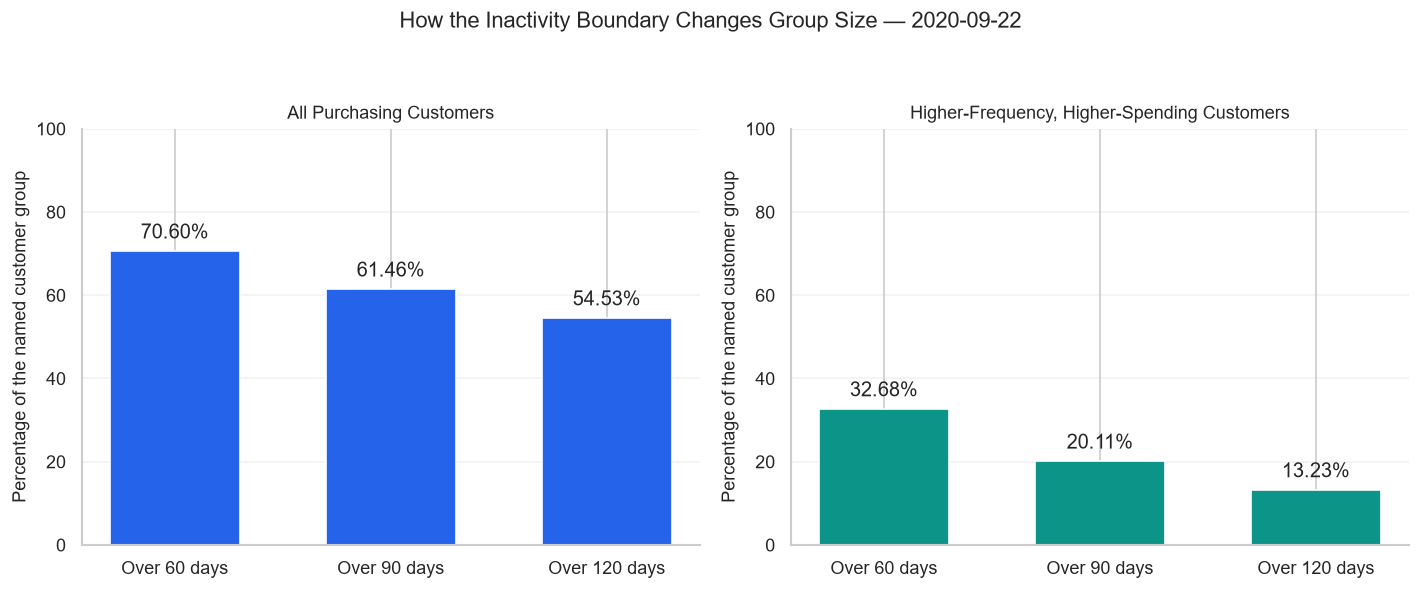

In [51]:
import matplotlib.pyplot as plt

labels = rfm_sensitivity["Boundary (days)"].map(
    lambda days: f"Over {days} days"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

panels = [
    (
        "Share of all customers (%)",
        "All Purchasing Customers",
        "#2563EB",
    ),
    (
        "Share of higher F/M group (%)",
        "Higher-Frequency, Higher-Spending Customers",
        "#0D9488",
    ),
]

for ax, (column, title, color) in zip(axes, panels):
    bars = ax.bar(
        labels,
        rfm_sensitivity[column],
        color=color,
        width=0.6,
    )

    ax.bar_label(bars, fmt="%.2f%%", padding=5)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Percentage of the named customer group")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    f"How the Inactivity Boundary Changes Group Size — {analysis_date}",
    fontsize=13,
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "25_recency_boundary_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

The share of higher-frequency, higher-spending customers exceeding
the inactivity boundary falls from 32.68% at 60 days to 13.23% at
120 days. Segment membership is therefore sensitive to the rule.

We retain 90 days as an exploratory segmentation boundary, not a
validated churn definition. A future prediction horizon must be
evaluated using historical cutoffs with complete follow-up periods.

In [52]:
import pandas as pd
from IPython.display import display

# Take a snapshot at the end of 2019.
# The next 90 days are fully covered by the dataset.
cutoff_date = "2019-12-31"

# Build customer RFM values using only transactions up to the snapshot.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE historical_rfm AS
SELECT
    customer_id,
    MAX(t_dat) AS last_purchase_date,
    DATEDIFF('day', MAX(t_dat), DATE '{cutoff_date}') AS recency_days,
    COUNT(DISTINCT t_dat) AS frequency_days,
    SUM(price) AS spending
FROM transactions
WHERE t_dat <= DATE '{cutoff_date}'
GROUP BY customer_id
""")

# Find the 75th-percentile cutoffs using snapshot data only.
# We'll use these to define higher-frequency and higher-spending customers.
cutoffs = con.execute("""
SELECT
    QUANTILE_CONT(frequency_days, 0.75) AS frequency_q75,
    QUANTILE_CONT(spending, 0.75) AS spending_q75
FROM historical_rfm
""").df()

display(cutoffs)

,frequency_q75,spending_q75
0,7.0,0.581


In [53]:
validation_result = con.execute(f"""
WITH thresholds AS (
    SELECT
        QUANTILE_CONT(frequency_days, 0.75) AS frequency_q75,
        QUANTILE_CONT(spending, 0.75) AS spending_q75
    FROM historical_rfm
),
returners AS (
    SELECT DISTINCT customer_id
    FROM transactions
    WHERE t_dat > DATE '{cutoff_date}'
      AND t_dat <= DATE '{cutoff_date}' + INTERVAL 90 DAY
),
boundaries AS (
    SELECT * FROM (VALUES (60), (90), (120)) AS b(inactivity_boundary_days)
)
SELECT
    b.inactivity_boundary_days,
    COUNT(*) AS customers_in_group,
    COUNT(r.customer_id) AS returned_within_90_days,
    COUNT(*) - COUNT(r.customer_id) AS did_not_return_within_90_days,
    ROUND(
        100.0 * COUNT(r.customer_id) / NULLIF(COUNT(*), 0),
        2
    ) AS return_rate_pct
FROM historical_rfm h
CROSS JOIN thresholds q
CROSS JOIN boundaries b
LEFT JOIN returners r
    ON h.customer_id = r.customer_id
WHERE h.recency_days > b.inactivity_boundary_days
  AND h.frequency_days >= q.frequency_q75
  AND h.spending >= q.spending_q75
GROUP BY b.inactivity_boundary_days
ORDER BY b.inactivity_boundary_days
""").df()

display(validation_result)

,inactivity_boundary_days,customers_in_group,returned_within_90_days,did_not_return_within_90_days,return_rate_pct
0,60,47638,28225,19413,59.25
1,90,26158,13895,12263,53.12
2,120,14776,6918,7858,46.82


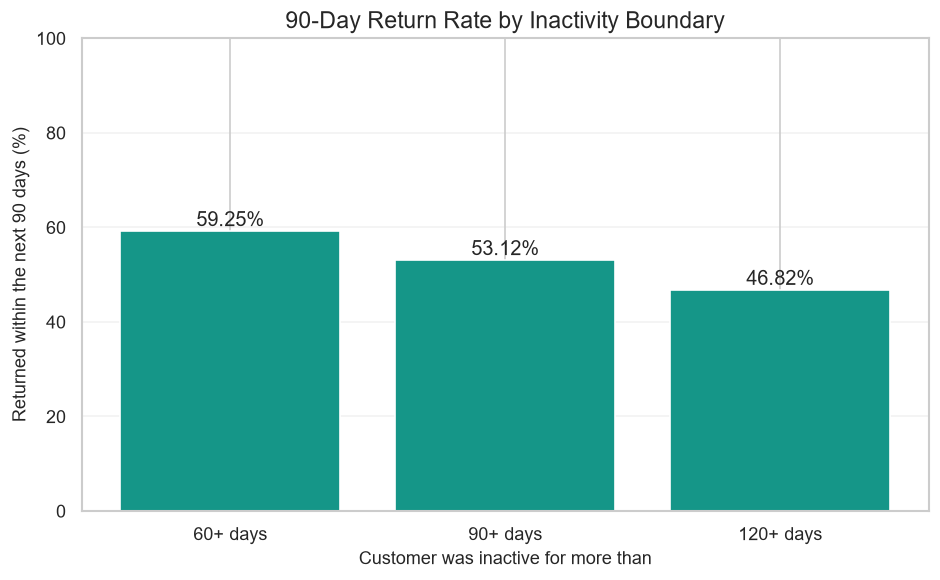

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    validation_result["inactivity_boundary_days"].astype(str) + "+ days",
    validation_result["return_rate_pct"],
    color="#159688"
)

plt.title("90-Day Return Rate by Inactivity Boundary")
plt.xlabel("Customer was inactive for more than")
plt.ylabel("Returned within the next 90 days (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)

for bar, rate in zip(bars, validation_result["return_rate_pct"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [55]:
# Create a 90-day outcome label using purchases after the historical cutoff.
# churn_90d = 1: no purchase in the next 90 days
# churn_90d = 0: at least one purchase in the next 90 days

con.execute(f"""
CREATE OR REPLACE TEMP TABLE historical_churn_labels AS
WITH future_returners AS (
    SELECT DISTINCT customer_id
    FROM transactions
    WHERE t_dat > DATE '{cutoff_date}'
      AND t_dat <= DATE '{cutoff_date}' + INTERVAL 90 DAY
)
SELECT
    h.customer_id,
    h.recency_days,
    h.frequency_days,
    h.spending,
    CASE
        WHEN r.customer_id IS NULL THEN 1
        ELSE 0
    END AS churn_90d
FROM historical_rfm h
LEFT JOIN future_returners r
    ON h.customer_id = r.customer_id
""")

# Check how many customers fall into each outcome group.
label_summary = con.execute("""
SELECT
    churn_90d,
    COUNT(*) AS customers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS customer_share_pct
FROM historical_churn_labels
GROUP BY churn_90d
ORDER BY churn_90d
""").df()

display(label_summary)

,churn_90d,customers,customer_share_pct
0,0,389053,34.83
1,1,727824,65.17


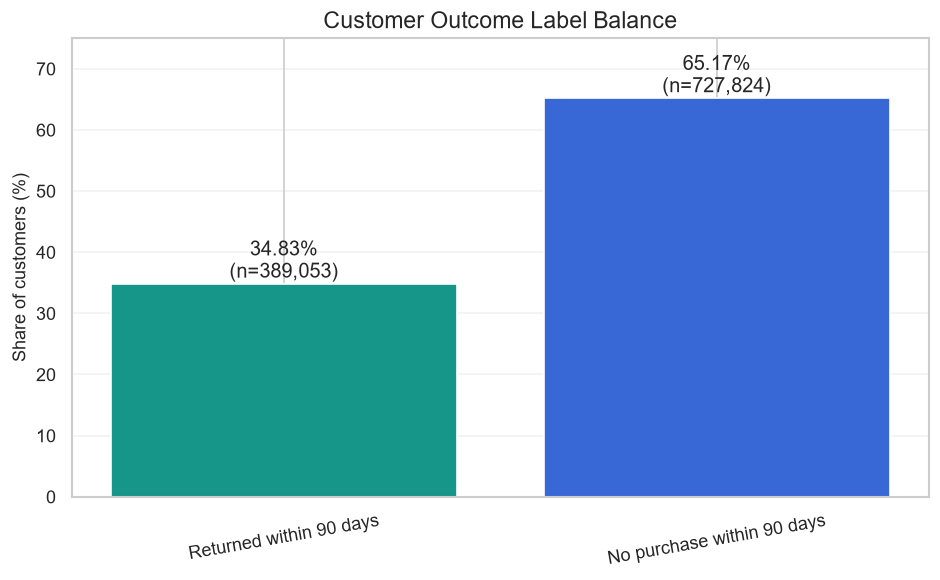

In [56]:
import matplotlib.pyplot as plt

outcome_names = {
    0: "Returned within 90 days",
    1: "No purchase within 90 days"
}

plot_data = label_summary.copy()
plot_data["outcome"] = plot_data["churn_90d"].map(outcome_names)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data["outcome"],
    plot_data["customer_share_pct"],
    color=["#159688", "#3867d6"]
)

ax.set_title("Customer Outcome Label Balance")
ax.set_ylabel("Share of customers (%)")
ax.set_ylim(0, 75)
ax.grid(axis="y", alpha=0.25)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{row['customer_share_pct']:.2f}%\n"
        f"(n={int(row['customers']):,})",
        ha="center"
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [57]:
con.execute(f"""
CREATE OR REPLACE TEMP TABLE historical_model_dataset AS
WITH transaction_history AS (
    SELECT *
    FROM transactions
    WHERE t_dat <= DATE '{cutoff_date}'
),
behavior_features AS (
    SELECT
        customer_id,

        -- Overall behavior observed by the cutoff
        COUNT(*) AS transaction_records,
        COUNT(DISTINCT t_dat) AS purchase_days,
        COUNT(DISTINCT article_id) AS distinct_articles,
        SUM(price) AS historical_spending,
        AVG(price) AS average_record_price,
        DATEDIFF('day', MIN(t_dat), DATE '{cutoff_date}') + 1
            AS customer_history_days,
        COUNT(DISTINCT DATE_TRUNC('month', t_dat)) AS active_months,

        -- Recent behavior before the cutoff
        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{cutoff_date}' - INTERVAL 30 DAY
            THEN t_dat
        END) AS purchase_days_last_30d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{cutoff_date}' - INTERVAL 90 DAY
            THEN t_dat
        END) AS purchase_days_last_90d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{cutoff_date}' - INTERVAL 180 DAY
            THEN t_dat
        END) AS purchase_days_last_180d,

        COUNT(DISTINCT CASE
            WHEN t_dat > DATE '{cutoff_date}' - INTERVAL 365 DAY
            THEN t_dat
        END) AS purchase_days_last_365d,

        -- Channel mix: channel 2 is Online; channel 1 is Store
        SUM(CASE WHEN sales_channel_id = 2 THEN 1 ELSE 0 END)
            AS online_records,

        1.0 * SUM(CASE WHEN sales_channel_id = 2 THEN 1 ELSE 0 END)
            / COUNT(*) AS online_record_share

    FROM transaction_history
    GROUP BY customer_id
)
SELECT
    b.*,
    l.churn_90d
FROM behavior_features b
INNER JOIN historical_churn_labels l
    ON b.customer_id = l.customer_id
""")

# Check the size and label counts of the resulting table.
feature_check = con.execute("""
SELECT
    COUNT(*) AS customer_rows,
    COUNT(DISTINCT customer_id) AS unique_customers,
    SUM(CASE WHEN churn_90d = 0 THEN 1 ELSE 0 END) AS returned_customers,
    SUM(CASE WHEN churn_90d = 1 THEN 1 ELSE 0 END) AS no_purchase_customers
FROM historical_model_dataset
""").df()

display(feature_check)

# Review the table's columns and data types.
display(con.execute("""
DESCRIBE historical_model_dataset
""").df())

,customer_rows,unique_customers,returned_customers,no_purchase_customers
0,1116877,1116877,389053.0,727824.0


,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,transaction_records,BIGINT,YES,None,None,None
2,purchase_days,BIGINT,YES,None,None,None
3,distinct_articles,BIGINT,YES,None,None,None
4,historical_spending,DOUBLE,YES,None,None,None
5,average_record_price,DOUBLE,YES,None,None,None
6,customer_history_days,BIGINT,YES,None,None,None
7,active_months,BIGINT,YES,None,None,None
8,purchase_days_last_30d,BIGINT,YES,None,None,None
9,purchase_days_last_90d,BIGINT,YES,None,None,None


In [58]:
feature_columns = [
    "transaction_records",
    "purchase_days",
    "distinct_articles",
    "historical_spending",
    "average_record_price",
    "customer_history_days",
    "active_months",
    "purchase_days_last_30d",
    "purchase_days_last_90d",
    "purchase_days_last_180d",
    "purchase_days_last_365d",
    "online_records",
    "online_record_share",
]

summary_queries = []

for column in feature_columns:
    summary_queries.append(f"""
        SELECT
            '{column}' AS feature,
            COUNT(*) AS customers,
            COUNT(*) - COUNT({column}) AS missing_values,
            MIN({column})::DOUBLE AS minimum,
            MEDIAN({column})::DOUBLE AS median,
            AVG({column})::DOUBLE AS mean,
            QUANTILE_CONT({column}, 0.95)::DOUBLE AS p95,
            MAX({column})::DOUBLE AS maximum
        FROM historical_model_dataset
    """)

feature_summary = con.execute(
    " UNION ALL ".join(summary_queries)
).df()

display(feature_summary.round(4))

,feature,customers,missing_values,minimum,median,mean,p95,maximum
0,transaction_records,1116877,0,1.0000,8.0000,18.6307,69.2000,1157.0000
1,purchase_days,1116877,0,1.0000,3.0000,5.3359,18.0000,265.0000
2,distinct_articles,1116877,0,1.0000,7.0000,16.0231,59.0000,859.0000
3,historical_spending,1116877,0,0.0008,0.2203,0.5251,2.0146,36.0518
4,average_record_price,1116877,0,0.0008,0.0264,0.0293,0.0525,0.5068
5,customer_history_days,1116877,0,1.0000,375.0000,325.4579,463.0000,468.0000
6,active_months,1116877,0,1.0000,2.0000,3.6420,11.0000,16.0000
7,purchase_days_last_30d,1116877,0,0.0000,0.0000,0.3242,2.0000,16.0000
8,purchase_days_last_90d,1116877,0,0.0000,0.0000,0.9900,4.0000,57.0000
9,purchase_days_last_180d,1116877,0,0.0000,1.0000,1.9951,8.0000,106.0000


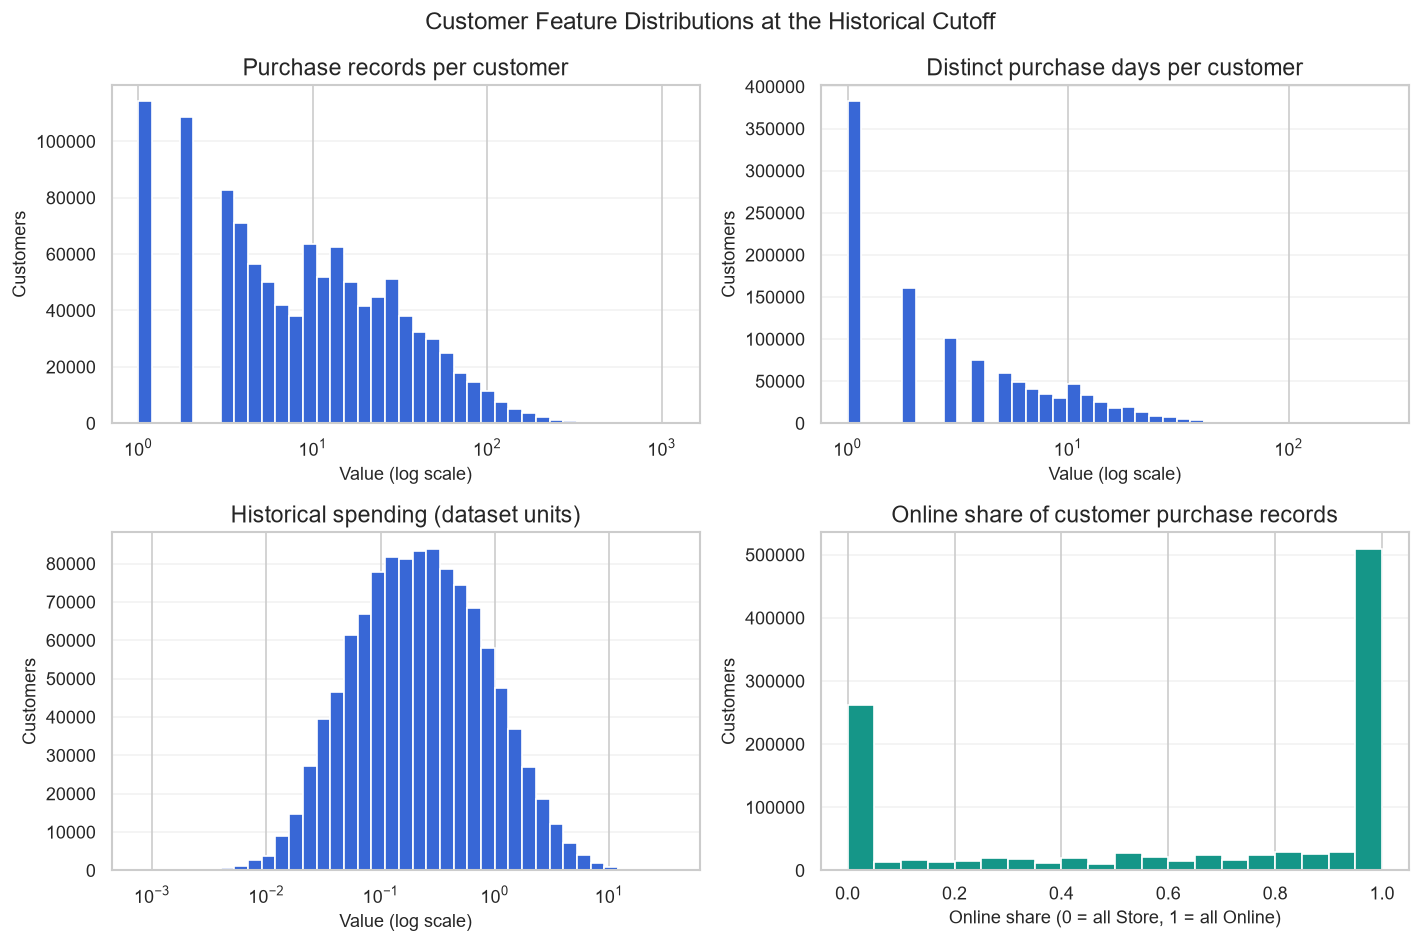

In [59]:
import numpy as np
import matplotlib.pyplot as plt

feature_plot_data = con.execute("""
SELECT
    transaction_records,
    purchase_days,
    historical_spending,
    online_record_share
FROM historical_model_dataset
""").df()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

skewed_features = [
    ("transaction_records", "Purchase records per customer"),
    ("purchase_days", "Distinct purchase days per customer"),
    ("historical_spending", "Historical spending (dataset units)"),
]

for ax, (column, title) in zip(axes.flat[:3], skewed_features):
    values = feature_plot_data[column]
    bins = np.geomspace(values.min(), values.max(), 40)

    ax.hist(values, bins=bins, color="#3867d6", edgecolor="white")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Value (log scale)")
    ax.set_ylabel("Customers")
    ax.grid(axis="y", alpha=0.25)

axes[1, 1].hist(
    feature_plot_data["online_record_share"],
    bins=np.linspace(0, 1, 21),
    color="#159688",
    edgecolor="white"
)
axes[1, 1].set_title("Online share of customer purchase records")
axes[1, 1].set_xlabel("Online share (0 = all Store, 1 = all Online)")
axes[1, 1].set_ylabel("Customers")
axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle("Customer Feature Distributions at the Historical Cutoff")
plt.tight_layout()
plt.show()

,band_order,prior_activity_band,customers,no_purchase_customers,no_purchase_rate_pct
0,0,0 days,601416,492753.0,81.93
1,1,1 day,260238,158751.0,61.00
2,2,2–3 days,178024,65154.0,36.60
3,3,4–7 days,67089,10752.0,16.03
4,4,8+ days,10110,414.0,4.09


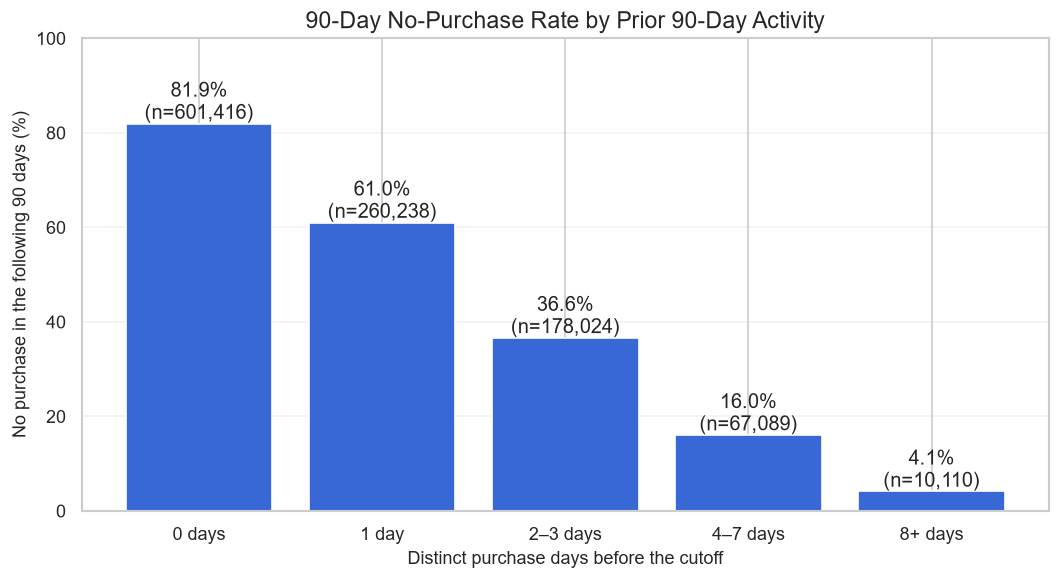

In [60]:
activity_churn = con.execute("""
WITH customer_groups AS (
    SELECT
        CASE
            WHEN purchase_days_last_90d = 0 THEN 0
            WHEN purchase_days_last_90d = 1 THEN 1
            WHEN purchase_days_last_90d BETWEEN 2 AND 3 THEN 2
            WHEN purchase_days_last_90d BETWEEN 4 AND 7 THEN 3
            ELSE 4
        END AS band_order,

        CASE
            WHEN purchase_days_last_90d = 0 THEN '0 days'
            WHEN purchase_days_last_90d = 1 THEN '1 day'
            WHEN purchase_days_last_90d BETWEEN 2 AND 3 THEN '2–3 days'
            WHEN purchase_days_last_90d BETWEEN 4 AND 7 THEN '4–7 days'
            ELSE '8+ days'
        END AS prior_activity_band,

        churn_90d
    FROM historical_model_dataset
)
SELECT
    band_order,
    prior_activity_band,
    COUNT(*) AS customers,
    SUM(churn_90d) AS no_purchase_customers,
    ROUND(100.0 * SUM(churn_90d) / COUNT(*), 2) AS no_purchase_rate_pct
FROM customer_groups
GROUP BY band_order, prior_activity_band
ORDER BY band_order
""").df()

display(activity_churn)

# Plot the 90-day no-purchase rate for each prior-activity group.
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    activity_churn["prior_activity_band"],
    activity_churn["no_purchase_rate_pct"],
    color="#3867d6"
)

ax.set_title("90-Day No-Purchase Rate by Prior 90-Day Activity")
ax.set_xlabel("Distinct purchase days before the cutoff")
ax.set_ylabel("No purchase in the following 90 days (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)

for bar, (_, row) in zip(bars, activity_churn.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{row['no_purchase_rate_pct']:.1f}%\n"
        f"(n={int(row['customers']):,})",
        ha="center"
    )

plt.tight_layout()
plt.show()

,spending_quintile,customers,median_historical_spending,no_purchase_customers,no_purchase_rate_pct,share_of_historical_spending_pct
0,1,223376,0.0406,197404.0,88.37,1.52
1,2,223376,0.1017,185005.0,82.82,4.01
2,3,223375,0.2203,159952.0,71.61,8.58
3,4,223375,0.4713,119575.0,53.53,18.58
4,5,223375,1.2867,65888.0,29.50,67.31


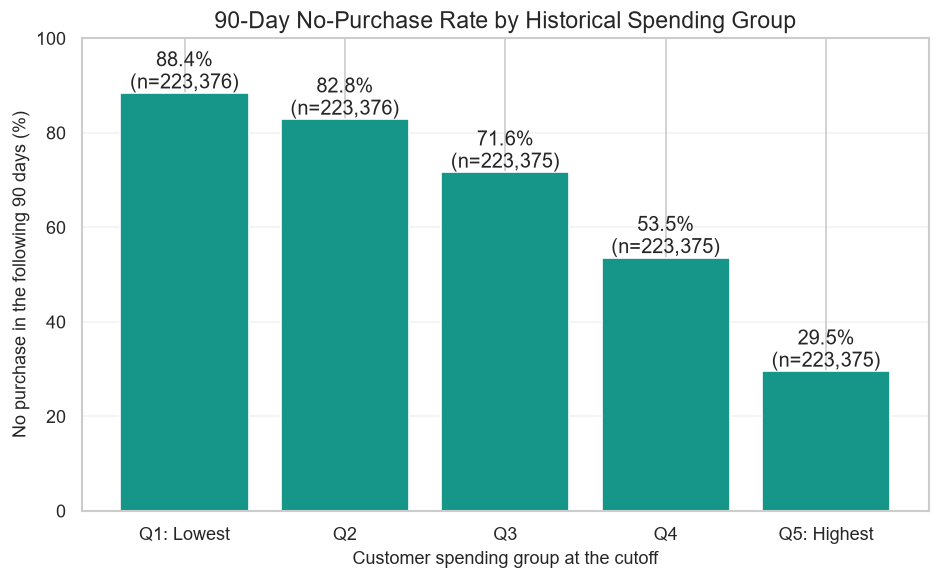

In [61]:
spending_churn = con.execute("""
WITH ranked_customers AS (
    SELECT
        historical_spending,
        churn_90d,
        NTILE(5) OVER (ORDER BY historical_spending) AS spending_quintile
    FROM historical_model_dataset
),
quintile_summary AS (
    SELECT
        spending_quintile,
        COUNT(*) AS customers,
        MEDIAN(historical_spending) AS median_historical_spending,
        SUM(churn_90d) AS no_purchase_customers,
        ROUND(
            100.0 * SUM(churn_90d) / COUNT(*),
            2
        ) AS no_purchase_rate_pct,
        SUM(historical_spending) AS group_historical_spending
    FROM ranked_customers
    GROUP BY spending_quintile
)
SELECT
    spending_quintile,
    customers,
    ROUND(median_historical_spending, 4) AS median_historical_spending,
    no_purchase_customers,
    no_purchase_rate_pct,
    ROUND(
        100.0 * group_historical_spending
        / SUM(group_historical_spending) OVER (),
        2
    ) AS share_of_historical_spending_pct
FROM quintile_summary
ORDER BY spending_quintile
""").df()

display(spending_churn)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Q1: Lowest", "Q2", "Q3", "Q4", "Q5: Highest"],
    spending_churn["no_purchase_rate_pct"],
    color="#159688"
)

ax.set_title("90-Day No-Purchase Rate by Historical Spending Group")
ax.set_xlabel("Customer spending group at the cutoff")
ax.set_ylabel("No purchase in the following 90 days (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)

for bar, (_, row) in zip(bars, spending_churn.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{row['no_purchase_rate_pct']:.1f}%\n"
        f"(n={int(row['customers']):,})",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [62]:
spending_value_risk = con.execute("""
WITH ranked_customers AS (
    SELECT
        historical_spending,
        churn_90d,
        NTILE(5) OVER (ORDER BY historical_spending) AS spending_quintile
    FROM historical_model_dataset
),
quintile_summary AS (
    SELECT
        spending_quintile,
        COUNT(*) AS customers,
        SUM(churn_90d) AS no_purchase_customers,
        SUM(historical_spending) AS total_group_historical_spending,
        SUM(
            CASE WHEN churn_90d = 1
                 THEN historical_spending
                 ELSE 0
            END
        ) AS no_purchase_group_historical_spending
    FROM ranked_customers
    GROUP BY spending_quintile
),
overall_spending AS (
    SELECT SUM(historical_spending) AS total_historical_spending
    FROM historical_model_dataset
)
SELECT
    q.spending_quintile,
    q.customers,
    q.no_purchase_customers,
    ROUND(100.0 * q.no_purchase_customers / q.customers, 2)
        AS no_purchase_rate_pct,
    ROUND(q.no_purchase_group_historical_spending, 2)
        AS past_spending_from_no_purchase_customers,
    ROUND(
        100.0 * q.no_purchase_group_historical_spending
        / NULLIF(q.total_group_historical_spending, 0),
        2
    ) AS pct_of_group_spending_from_no_purchase_customers,
    ROUND(
        100.0 * q.no_purchase_group_historical_spending
        / NULLIF(o.total_historical_spending, 0),
        2
    ) AS pct_of_all_past_spending_from_no_purchase_customers
FROM quintile_summary q
CROSS JOIN overall_spending o
ORDER BY q.spending_quintile
""").df()

display(spending_value_risk)

,spending_quintile,customers,no_purchase_customers,no_purchase_rate_pct,past_spending_from_no_purchase_customers,pct_of_group_spending_from_no_purchase_customers,pct_of_all_past_spending_from_no_purchase_customers
0,1,223376,197402.0,88.37,7827.43,87.92,1.33
1,2,223376,185001.0,82.82,19338.11,82.22,3.30
2,3,223375,159962.0,71.61,35596.96,70.73,6.07
3,4,223375,119571.0,53.53,56803.94,52.12,9.69
4,5,223375,65888.0,29.50,92322.10,23.39,15.74


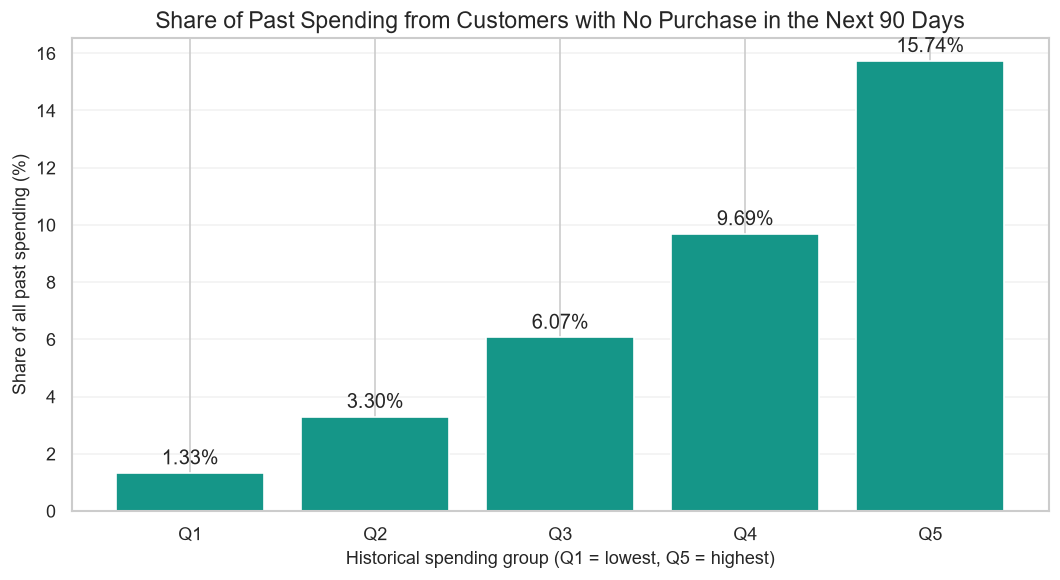

In [63]:
fig, ax = plt.subplots(figsize=(9, 5))

quintile_labels = [
    f"Q{q}" for q in spending_value_risk["spending_quintile"]
]

bars = ax.bar(
    quintile_labels,
    spending_value_risk[
        "pct_of_all_past_spending_from_no_purchase_customers"
    ],
    color="#159688"
)

ax.set_title(
    "Share of Past Spending from Customers with No Purchase in the Next 90 Days"
)
ax.set_xlabel("Historical spending group (Q1 = lowest, Q5 = highest)")
ax.set_ylabel("Share of all past spending (%)")
ax.grid(axis="y", alpha=0.25)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [64]:
# Check the final modeling table before saving it.
missing_feature_condition = " OR ".join(
    f"{column} IS NULL" for column in feature_columns
)

nonfinite_condition = " OR ".join(
    f"NOT isfinite({column})"
    for column in [
        "historical_spending",
        "average_record_price",
        "online_record_share",
    ]
)

final_audit = con.execute(f"""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT customer_id) AS unique_customers,
    COUNT(*) - COUNT(DISTINCT customer_id) AS duplicate_customer_rows,

    SUM(CASE WHEN ({missing_feature_condition})
             THEN 1 ELSE 0 END) AS rows_with_missing_features,

    SUM(CASE WHEN churn_90d IS NULL
             THEN 1 ELSE 0 END) AS rows_with_missing_target,

    SUM(CASE WHEN churn_90d NOT IN (0, 1)
             THEN 1 ELSE 0 END) AS rows_with_invalid_target,

    SUM(CASE WHEN ({nonfinite_condition})
             THEN 1 ELSE 0 END) AS rows_with_nonfinite_values
FROM historical_model_dataset
""").df()

display(final_audit)

# Save only if the audit is clean.
audit_row = final_audit.iloc[0]

checks_to_pass = [
    audit_row["rows"] == audit_row["unique_customers"],
    audit_row["duplicate_customer_rows"] == 0,
    audit_row["rows_with_missing_features"] == 0,
    audit_row["rows_with_missing_target"] == 0,
    audit_row["rows_with_invalid_target"] == 0,
    audit_row["rows_with_nonfinite_values"] == 0,
]

if not all(checks_to_pass):
    raise ValueError("The final audit found an issue. Review the table before saving.")

output_file = (
    project_root
    / "data"
    / "processed"
    / "customer_churn_model_2019-12-31.parquet"
)

output_file.parent.mkdir(parents=True, exist_ok=True)
output_sql_path = str(output_file).replace("'", "''")

con.execute(f"""
COPY (
    SELECT *
    FROM historical_model_dataset
)
TO '{output_sql_path}'
(FORMAT PARQUET, COMPRESSION ZSTD)
""")

saved_rows = con.execute(
    f"SELECT COUNT(*) FROM read_parquet('{output_sql_path}')"
).fetchone()[0]

print(f"Saved file: {output_file}")
print(f"Rows verified in saved file: {saved_rows:,}")
print(f"File size: {output_file.stat().st_size / (1024 ** 2):,.2f} MiB")

,rows,unique_customers,duplicate_customer_rows,rows_with_missing_features,rows_with_missing_target,rows_with_invalid_target,rows_with_nonfinite_values
0,1116877,1116877,0,0.0,0.0,0.0,0.0


Saved file: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_churn_model_2019-12-31.parquet
Rows verified in saved file: 1,116,877
File size: 53.91 MiB
